## 1. Data Partitioning and On-the-Fly Preprocessing

To evaluate the experimental prototype objectively, the dataset is partitioned into three independent subsets: Training (70%), Validation (15%), and Test (15%). The Validation set is strictly used for hyperparameter tuning and model selection, while the Test set is isolated for the final inference analysis to prevent data leakage.

Due to the memory constraints of medical imaging datasets, a custom `tf.keras.utils.Sequence` generator is implemented. This generator executes the following methodological steps on-the-fly:
1. **Radiological HU Windowing:** CT voxel densities are clipped to the [-30.0, 150.0] range. This is a methodological choice to attenuate bone and visceral fat noise, isolating striated skeletal muscle density prior to neural network inference.
2. **Min-Max Normalization:** The clipped HU values are mapped to a [0, 1] range to ensure gradient stability during training.
3. **Categorical Integrity:** The segmentation masks must retain their three distinct classification categories (0: Background, 1: Abdominal, 2: Psoas). They are explicitly protected from the [0, 1] normalization applied to the CT slices.
4. **Spatial Resampling:** Images are resized to 256x256 using bilinear interpolation, whereas masks are resized using nearest-neighbor interpolation to strictly preserve the discrete `[0, 1, 2]` integer labels.

In [5]:
%pip install tensorflow scikit-learn nibabel numpy scipy pandas matplotlib seaborn ipykernel

     ---------------------------------------- 0.0/61.0 kB ? eta -:--:--
     -------------------- ------------------- 30.7/61.0 kB ? eta -:--:--
     -------------------- ------------------- 30.7/61.0 kB ? eta -:--:--
     ------------------------------- ------ 51.2/61.0 kB 375.8 kB/s eta 0:00:01
     -------------------------------------- 61.0/61.0 kB 405.7 kB/s eta 0:00:00
     ---------------------------------------- 0.0/47.3 kB ? eta -:--:--
     ---------------------------------------- 47.3/47.3 kB 1.2 MB/s eta 0:00:00
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.3 MB 1.9 MB/s eta 0:00:05
   ---------------------------------------- 0.0/8.3 MB 1.9 MB/s eta 0:00:05
    --------------------------------------- 0.1/8.3 MB 1.1 MB/s eta 0:00:08
    --------------------------------------- 0.1/8.3 MB 1.1 MB/s eta 0:00:08
    --------------------------------------- 0.2/8.3 MB 958.4 kB/s eta 0:00:09
   - --------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     --------------- ------------------------ 30.7/80.3 kB ? eta -:--:--
     ------------------- ------------------ 41.0/80.3 kB 393.8 kB/s eta 0:00:01
     --------------------------------- ---- 71.7/80.3 kB 491.5 kB/s eta 0:00:01
     -------------------------------------- 80.3/80.3 kB 496.6 kB/s eta 0:00:00
     ---------------------------------------- 0.0/139.8 kB ? eta -:--:--
     ------------------- ------------------- 71.7/139.8 kB 3.8 MB/s eta 0:00:01
     ------------------- ------------------- 71.7/139.8 kB 3.8 MB/s eta 0:00:01
     ---------------------------------- - 133.1/139.8 kB 983.0 kB/s eta 0:00:01
     ------------------------------------ 139.8/139.8 kB 830.5 kB/s eta 0:00:00
   ---------------------------------------- 0.0/11.0 MB ? eta -:--:--
    --------------------------------------- 0.2/11.0 MB 13.4 MB/s eta 0:00:01
    --------------------------------------- 0.2/11.0 MB 13.4 MB/s eta 0:00

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from sklearn.model_selection import train_test_split
from pathlib import Path
import math
import numpy as np
import nibabel as nib
import tensorflow as tf

# 1. Path Definitions
DIR_IMMAGINI = Path(r"C:\Users\vella\Desktop\tirocinio\Dataset\slices")
DIR_MASCHERE = Path(r"C:\Users\vella\Desktop\tirocinio\Dataset\masks")

tutte_le_immagini = sorted(list(DIR_IMMAGINI.glob("*.nii")))
tutte_le_maschere = sorted(list(DIR_MASCHERE.glob("*.nii")))

# 2. Methodological Data Partitioning (70% / 15% / 15%)
# First split: 70% Train, 30% Temporary (Validation + Test)
train_img, temp_img, train_mask, temp_mask = train_test_split(
    tutte_le_immagini, tutte_le_maschere, test_size=0.30, random_state=42
)

# Second split: Divide the 30% Temporary into 15% Validation and 15% Test
val_img, test_img, val_mask, test_mask = train_test_split(
    temp_img, temp_mask, test_size=0.50, random_state=42
)

print(f"Training set (Weight Optimization): {len(train_img)} patients")
print(f"Validation set (Hyperparameter Tuning): {len(val_img)} patients")
print(f"Test set (Final Inference Analysis): {len(test_img)} patients")

# 3. Keras Sequence Generator Definition
class L3MuscleDataGenerator(tf.keras.utils.Sequence):
    def __init__(self, lista_immagini, lista_maschere, batch_size=4, target_size=(256, 256)):
        self.lista_immagini = lista_immagini
        self.lista_maschere = lista_maschere
        self.batch_size = batch_size
        self.target_size = target_size

    def __len__(self):
        return math.ceil(len(self.lista_immagini) / self.batch_size)

    def __getitem__(self, idx):
        batch_x_paths = self.lista_immagini[idx * self.batch_size : (idx + 1) * self.batch_size]
        batch_y_paths = self.lista_maschere[idx * self.batch_size : (idx + 1) * self.batch_size]

        batch_x, batch_y = [], []

        for img_path, mask_path in zip(batch_x_paths, batch_y_paths):
            # Load raw NIfTI arrays
            img_np = np.squeeze(nib.load(img_path).get_fdata())
            mask_np = np.squeeze(nib.load(mask_path).get_fdata())

            # Radiological Windowing [-30, 150] and Min-Max Normalization [0, 1] for CT data
            HU_MIN, HU_MAX = -30.0, 150.0
            img_np = np.clip(img_np, HU_MIN, HU_MAX)
            img_np = (img_np - HU_MIN) / (HU_MAX - HU_MIN) 

            # Note: Mask data (mask_np) bypasses normalization to preserve classes 0, 1, 2.

            # Convert to Tensors and expand channel dimension
            img_tensor = tf.expand_dims(tf.convert_to_tensor(img_np, dtype=tf.float32), axis=-1) 
            mask_tensor = tf.expand_dims(tf.convert_to_tensor(mask_np, dtype=tf.int32), axis=-1)

            # Spatial Resampling
            img_resized = tf.image.resize(img_tensor, self.target_size, method='bilinear')
            mask_resized = tf.image.resize(mask_tensor, self.target_size, method='nearest')

            batch_x.append(img_resized.numpy())
            batch_y.append(mask_resized.numpy())

        return np.array(batch_x), np.array(batch_y)

# 4. Initialization of Generators
train_generator = L3MuscleDataGenerator(train_img, train_mask, batch_size=4)
val_generator = L3MuscleDataGenerator(val_img, val_mask, batch_size=4)
test_generator = L3MuscleDataGenerator(test_img, test_mask, batch_size=4)

Training set (Weight Optimization): 147 patients
Validation set (Hyperparameter Tuning): 32 patients
Test set (Final Inference Analysis): 32 patients


## 2. Objective Functions and Evaluation Metrics

In abdominal CT segmentation, target muscle structures occupy a small fraction of the total slice volume relative to the unclassified background. Standard pixel-wise metrics, such as Accuracy or unweighted Cross-Entropy, suffer from extreme class imbalance, leading to models biased toward background prediction.

To establish mathematical and optimization stability, we implement a **Combined Loss Function** alongside class-wise overlap metrics.

### 2.1 Mathematical Formulation of Objective Functions

#### 1. Sparse Categorical Cross-Entropy ($L_{SCCE}$)
$L_{SCCE}$ measures pixel-wise probabilistic cross-entropy across all classes (including background), providing smooth gradients early in training:

$$L_{SCCE} = -\frac{1}{N} \sum_{i=1}^{N} \sum_{c=0}^{C-1} y_{i,c} \log(\hat{y}_{i,c})$$

where $N$ is the total number of pixels, $C=3$ is the number of target classes, $y_{i,c} \in \{0, 1\}$ is the indicator that pixel $i$ belongs to class $c$, and $\hat{y}_{i,c}$ is the predicted probability.

#### 2. Class-Wise Foreground Dice Loss ($L_{Dice}$)
To directly optimize spatial overlap while ignoring background dominance, we formulate a multi-class Dice loss restricted to the foreground muscle structures: $C_{fg} = \{1: \text{Abdominals}, 2: \text{Psoas}\}$.

For each foreground class $c \in C_{fg}$, the Dice coefficient is defined as:

$$Dice_c = \frac{2 \sum_{i=1}^{N} y_{i,c} \hat{y}_{i,c} + \epsilon}{\sum_{i=1}^{N} y_{i,c} + \sum_{i=1}^{N} \hat{y}_{i,c} + \epsilon}$$

where $\epsilon = 10^{-6}$ is a Laplacian smoothing constant preventing division by zero and numerical instability when a class is absent in a given slice. The overall Dice loss is the unweighted average complement across foreground classes:

$$L_{Dice} = 1 - \frac{1}{|C_{fg}|} \sum_{c \in C_{fg}} Dice_c$$

#### 3. Combined Loss ($L_{Total}$)
The total objective function combines $L_{SCCE}$ and $L_{Dice}$ with equal weighting ($\lambda = 1.0$), balancing pixel-level probabilistic calibration with global shape alignment:

$$L_{Total} = L_{SCCE} + L_{Dice}$$

---

### 2.2 Complementary Overlap Metric: Intersection over Union (IoU / Jaccard Index)

To provide a standard benchmark alongside the Dice coefficient, we also compute the class-wise Jaccard Index ($IoU_c$):

$$IoU_c = \frac{\sum_{i=1}^{N} y_{i,c} \hat{y}_{i,c} + \epsilon}{\sum_{i=1}^{N} y_{i,c} + \sum_{i=1}^{N} \hat{y}_{i,c} - \sum_{i=1}^{N} y_{i,c} \hat{y}_{i,c} + \epsilon}$$

---

### Methodological References
* **Milletari, F., Navab, N., & Ahmadi, S. A. (2016).** V-Net: Fully Convolutional Neural Networks for Volumetric Medical Image Segmentation. *2016 Fourth International Conference on 3D Vision (3DV)*, 565-571. DOI: [10.1109/3DV.2016.79](https://doi.org/10.1109/3DV.2016.79)
* **Jaccard, P. (1912).** The distribution of the flora in the alpine zone. *New Phytologist*, 11(2), 37-50. DOI: [10.1111/j.1469-8137.1912.tb05611.x](https://doi.org/10.1111/j.1469-8137.1912.tb05611.x)
* **Yeung, M., et al. (2022).** Unified Focal loss: Generalising Dice and cross entropy-based losses to handle class imbalance of medical image segmentation. *Computerized Medical Imaging and Graphics*, 95, 102026. DOI: [10.1016/j.compmedimag.2021.102026](https://doi.org/10.1016/j.compmedimag.2021.102026)

In [2]:
import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.losses import SparseCategoricalCrossentropy

def class_wise_dice_coef(y_true, y_pred, smooth=1e-6):
    """
    Computes class-wise Dice Coefficients for foreground classes (Class 1: Abdominals, Class 2: Psoas),
    explicitly ignoring background (Class 0).
    
    Ref: Milletari et al. (2016), DOI: 10.1109/3DV.2016.79
    
    Returns:
        Tensor of shape (2,) containing [Dice_Class1, Dice_Class2]
    """
    # 1. Ensure target tensor format and convert ground truth to One-Hot encoding (depth=3)
    if len(y_true.shape) == 4 and y_true.shape[-1] == 1:
        y_true = tf.squeeze(y_true, axis=-1)
    y_true = tf.cast(y_true, tf.int32)
    y_true_one_hot = tf.one_hot(y_true, depth=3)  # Shape: (batch, H, W, 3)
    y_true_one_hot = tf.cast(y_true_one_hot, tf.float32)

    # 2. Extract foreground classes (Class 1 and Class 2 only)
    y_true_fg = y_true_one_hot[..., 1:]  # Shape: (batch, H, W, 2)
    y_pred_fg = y_pred[..., 1:]          # Shape: (batch, H, W, 2)

    # 3. Sum over spatial dimensions (Height, Width)
    spatial_axes = [1, 2]
    intersection = K.sum(y_true_fg * y_pred_fg, axis=spatial_axes)
    denominator = K.sum(y_true_fg, axis=spatial_axes) + K.sum(y_pred_fg, axis=spatial_axes)

    # 4. Compute batch-averaged Dice per class
    dice_per_class_batch = (2.0 * intersection + smooth) / (denominator + smooth)
    dice_per_class = K.mean(dice_per_class_batch, axis=0)  # Shape: (2,)
    
    return dice_per_class

def mean_muscle_dice_coef(y_true, y_pred, smooth=1e-6):
    """Computes the mean Dice Coefficient across foreground muscle classes."""
    dice_per_class = class_wise_dice_coef(y_true, y_pred, smooth=smooth)
    return K.mean(dice_per_class)

def class_wise_iou_coef(y_true, y_pred, smooth=1e-6):
    """
    Computes class-wise Intersection over Union (Jaccard Index) for Class 1 and Class 2.
    
    Ref: Jaccard, P. (1912), DOI: 10.1111/j.1469-8137.1912.tb05611.x
    
    Returns:
        Tensor of shape (2,) containing [IoU_Class1, IoU_Class2]
    """
    if len(y_true.shape) == 4 and y_true.shape[-1] == 1:
        y_true = tf.squeeze(y_true, axis=-1)
    y_true = tf.cast(y_true, tf.int32)
    y_true_one_hot = tf.one_hot(y_true, depth=3)
    y_true_one_hot = tf.cast(y_true_one_hot, tf.float32)

    y_true_fg = y_true_one_hot[..., 1:]
    y_pred_fg = y_pred[..., 1:]

    spatial_axes = [1, 2]
    intersection = K.sum(y_true_fg * y_pred_fg, axis=spatial_axes)
    total_area = K.sum(y_true_fg, axis=spatial_axes) + K.sum(y_pred_fg, axis=spatial_axes)
    union = total_area - intersection

    iou_per_class_batch = (intersection + smooth) / (union + smooth)
    iou_per_class = K.mean(iou_per_class_batch, axis=0)
    
    return iou_per_class

def mean_muscle_iou_coef(y_true, y_pred, smooth=1e-6):
    """Computes the mean IoU (Jaccard Index) across foreground muscle classes."""
    iou_per_class = class_wise_iou_coef(y_true, y_pred, smooth=smooth)
    return K.mean(iou_per_class)

def muscle_dice_loss(y_true, y_pred):
    """Dice Loss complement across foreground classes."""
    return 1.0 - mean_muscle_dice_coef(y_true, y_pred)

def combined_loss(y_true, y_pred):
    """
    Combined Loss Function: Sparse Categorical Cross-Entropy + Foreground Dice Loss.
    
    L_total = L_SCCE + L_Dice
    """
    scce_loss = SparseCategoricalCrossentropy()(y_true, y_pred)
    dice_l = muscle_dice_loss(y_true, y_pred)
    return scce_loss + dice_l

## 3. Physical Boundary Evaluation Metrics

While the Dice Coefficient and Jaccard Index (IoU) effectively measure volumetric overlap, clinical segmentation requires precise anatomical boundary delineation. Volumetric metrics can be misleadingly high if the overall volume overlaps, even if the predicted boundary is highly irregular.

To evaluate morphological precision, we compute the Hausdorff Distance dynamically in **millimeters (mm)** by extracting the exact physical voxel spacing $(dx, dy)$ from the native NIfTI headers.

### 3.1 95th Percentile Hausdorff Distance ($HD_{95}$)
The standard Maximum Hausdorff Distance ($HD_{max}$) measures the absolute largest error between the predicted boundary $Y$ and the ground truth boundary $X$:

$$HD_{max}(X, Y) = \max \left( \sup_{x \in X} \inf_{y \in Y} d(x,y), \sup_{y \in Y} \inf_{x \in X} d(x,y) \right)$$

However, $HD_{max}$ is highly susceptible to isolated outlier pixels (e.g., a single false-positive voxel located far from the main muscle body). To provide a robust clinical metric, we implement the 95th Percentile Hausdorff Distance ($HD_{95}$). By evaluating the 95th percentile of the minimum distances instead of the supremum, the metric ignores the top 5% of extreme spatial outliers, yielding a much more reliable assessment of general boundary adherence.

### 3.2 Balanced Average Hausdorff Distance (bAHD)
As a supplementary metric to $HD_{95}$, we maintain the computation of the Balanced Average Hausdorff Distance, which calculates the mean absolute error across the entire contour, providing insight into the general concentric alignment of the predicted mask.

---
### Methodological References
* **Huttenlocher, D. P., Klanderman, G. A., & Rucklidge, W. J. (1993).** Comparing images using the Hausdorff distance. *IEEE Transactions on Pattern Analysis and Machine Intelligence*, 15(9), 850-863. DOI: [10.1109/34.232073](https://doi.org/10.1109/34.232073)

In [3]:
import numpy as np
from scipy.ndimage import binary_erosion
from scipy.spatial import cKDTree

def get_boundary_coordinates(mask):
    """
    Extracts the pixel coordinates of the boundary of a binary mask
    using morphological erosion. Boundary = Original - Eroded.
    """
    eroded_mask = binary_erosion(mask)
    boundary = mask ^ eroded_mask 
    return np.argwhere(boundary)

def calculate_HD95_single_class_mm(y_true_binary, y_pred_binary, spacing_y_mm, spacing_x_mm):
    """
    Calculates the 95th Percentile Hausdorff Distance (HD95) for a single binary class in millimeters.
    This provides robust boundary error evaluation while ignoring extreme single-pixel outliers.
    """
    X = get_boundary_coordinates(y_true_binary)
    Y = get_boundary_coordinates(y_pred_binary)
    
    if len(X) == 0 and len(Y) == 0:
        return 0.0
    if len(X) == 0 or len(Y) == 0:
        return np.nan 
        
    # Convert pixel coordinates to physical millimeter space
    X_mm = X * np.array([spacing_y_mm, spacing_x_mm])
    Y_mm = Y * np.array([spacing_y_mm, spacing_x_mm])
    
    tree_X = cKDTree(X_mm)
    tree_Y = cKDTree(Y_mm)
    
    dist_X_to_Y, _ = tree_Y.query(X_mm)
    dist_Y_to_X, _ = tree_X.query(Y_mm)
    
    # Calculate the 95th percentile instead of the absolute maximum
    hd95_X = np.percentile(dist_X_to_Y, 95)
    hd95_Y = np.percentile(dist_Y_to_X, 95)
    
    hd95_mm = max(hd95_X, hd95_Y)
    
    return hd95_mm

def calculate_bAHD_single_class_mm(y_true_binary, y_pred_binary, spacing_y_mm, spacing_x_mm):
    """
    Calculates the Balanced Average Hausdorff Distance (bAHD) in millimeters.
    """
    X = get_boundary_coordinates(y_true_binary)
    Y = get_boundary_coordinates(y_pred_binary)
    
    if len(X) == 0 and len(Y) == 0:
        return 0.0
    if len(X) == 0 or len(Y) == 0:
        return np.nan 
        
    X_mm = X * np.array([spacing_y_mm, spacing_x_mm])
    Y_mm = Y * np.array([spacing_y_mm, spacing_x_mm])
    
    tree_X = cKDTree(X_mm)
    tree_Y = cKDTree(Y_mm)
    
    dist_X_to_Y, _ = tree_Y.query(X_mm)
    sum_dist_X = np.sum(dist_X_to_Y)
    
    dist_Y_to_X, _ = tree_X.query(Y_mm)
    sum_dist_Y = np.sum(dist_Y_to_X)
    
    bahd_mm = (sum_dist_X + sum_dist_Y) / (len(X) + len(Y))
    
    return bahd_mm

## 4. Methodological Configuration of the U-Net Architecture

The segmentation engine utilizes an adapted configuration of the canonical U-Net architecture proposed by Ronneberger et al. (2015). While the fundamental fully convolutional encoder-decoder topology remains standard, specific architectural hyper-parameters were modified to address the unique textures of striated skeletal muscle in CT data.

1. **Augmented Filter Depth:** The network capacity was deepened, utilizing a filter sequence of `[16, 32, 64, 128, 256]`. This allows the deeper bottleneck layers to extract highly complex spatial representations of the muscle fascia.
2. **Regularization:** To mitigate overfitting on a restricted experimental dataset, `BatchNormalization` is applied to stabilize layer activations, and aggressive `Dropout` (ranging from 0.1 to 0.3) is injected between convolution blocks.
3. **Optimization Strategy:** The network is optimized using the Adam optimizer (learning rate $10^{-3}$) targeting the custom Combined Loss function. A `ModelCheckpoint` monitors the validation loss, exclusively preserving the weight matrix that yields the lowest loss, thereby preventing model degradation in later epochs.

---
### Methodological References
* **Ronneberger, O., Fischer, P., & Brox, T. (2015).** U-Net: Convolutional Networks for Biomedical Image Segmentation. *Medical Image Computing and Computer-Assisted Intervention (MICCAI)*, 234-241. DOI: [10.1007/978-3-319-24574-4_28](https://doi.org/10.1007/978-3-319-24574-4_28)

In [ ]:
from tensorflow import keras
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Dropout, Conv2DTranspose, concatenate, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import ModelCheckpoint

# Base configurations
img_size = (256, 256)
num_classes = 3 # 0: Background, 1: Abdominals, 2: Psoas
filters = [16, 32, 64, 128, 256] 
i = 0

inputs = Input(shape=img_size + (1,))
s = inputs 

# --- ENCODER ---
c1 = Conv2D(filters[i], (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(s)
c1 = BatchNormalization()(c1)
c1 = Dropout(0.1)(c1)
c1 = Conv2D(filters[i], (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c1)
p1 = MaxPooling2D((2, 2))(c1)
i += 1

c2 = Conv2D(filters[i], (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p1)
c2 = Dropout(0.1)(c2)
c2 = Conv2D(filters[i], (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c2)
p2 = MaxPooling2D((2, 2))(c2)
i += 1

c3 = Conv2D(filters[i], (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p2)
c3 = Dropout(0.2)(c3)
c3 = Conv2D(filters[i], (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c3)
p3 = MaxPooling2D((2, 2))(c3)
i += 1

c4 = Conv2D(filters[i], (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p3)
c4 = Dropout(0.2)(c4)
c4 = Conv2D(filters[i], (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c4)
p4 = MaxPooling2D(pool_size=(2, 2))(c4)
i += 1

# --- BOTTLENECK ---
c5 = Conv2D(filters[i], (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(p4)
c5 = Dropout(0.3)(c5)
c5 = Conv2D(filters[i], (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c5)
i -= 1

# --- DECODER ---
u6 = Conv2DTranspose(filters[i], (2, 2), strides=(2,2), padding='same')(c5)
u6 = concatenate([u6, c4])
c6 = Conv2D(filters[i], (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u6)
c6 = Dropout(0.2)(c6)
c6 = Conv2D(filters[i], (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c6)
i -= 1

u7 = Conv2DTranspose(filters[i], (2, 2), strides=(2, 2), padding='same')(c6)
u7 = concatenate([u7, c3])
c7 = Conv2D(filters[i], (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u7)
c7 = Dropout(0.2)(c7)
c7 = Conv2D(filters[i], (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c7)
i -= 1

u8 = Conv2DTranspose(filters[i], (2, 2), strides=(2, 2), padding='same')(c7)
u8 = concatenate([u8, c2])
c8 = Conv2D(filters[i], (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u8)
c8 = Dropout(0.1)(c8)
c8 = Conv2D(filters[i], (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c8)
i -= 1

u9 = Conv2DTranspose(filters[i], (2, 2), strides=(2, 2), padding='same')(c8)
u9 = concatenate([u9, c1], axis=3)
c9 = Conv2D(filters[i], (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(u9)
c9 = Dropout(0.1)(c9)
c9 = Conv2D(filters[i], (3, 3), activation='relu', kernel_initializer='he_normal', padding='same')(c9)

# --- OUTPUT LAYER ---
outputs = Conv2D(num_classes, 3, padding='same', activation='softmax')(c9)
model = Model(inputs=[inputs], outputs=[outputs])

# Compilation with updated objective functions and explicit metrics
lr = 0.001
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=lr),
    loss=combined_loss,
    metrics=[mean_muscle_dice_coef, mean_muscle_iou_coef, 'accuracy']
)

filepath = "unet_sarcopenia_best.keras"
checkpoint = ModelCheckpoint(filepath, monitor='val_loss', verbose=1, save_best_only=True, mode='min')
callbacks_list = [checkpoint]

In [5]:
# Proceeding to training
print("Initializing model optimization...")
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=50,
    callbacks=callbacks_list,
    verbose=1
)

Initializing model optimization...


c:\Users\vella\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 244ms/step - accuracy: 0.8659 - loss: 1.2129 - mean_muscle_dice_coef: 0.1411 - mean_muscle_iou_coef: 0.0798

c:\Users\vella\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()



Epoch 1: val_loss improved from None to 1.37133, saving model to unet_sarcopenia_best.keras

Epoch 1: finished saving model to unet_sarcopenia_best.keras
37/37 ━━━━━━━━━━━━━━━━━━━━ 15s 289ms/step - accuracy: 0.8659 - loss: 1.2129 - mean_muscle_dice_coef: 0.1411 - mean_muscle_iou_coef: 0.0798 - val_accuracy: 0.8801 - val_loss: 1.3713 - val_mean_muscle_dice_coef: 0.1039 - val_mean_muscle_iou_coef: 0.0562
Epoch 2/50
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 243ms/step - accuracy: 0.9053 - loss: 0.9702 - mean_muscle_dice_coef: 0.2265 - mean_muscle_iou_coef: 0.1359
Epoch 2: val_loss improved from 1.37133 to 1.17942, saving model to unet_sarcopenia_best.keras

Epoch 2: finished saving model to unet_sarcopenia_best.keras
37/37 ━━━━━━━━━━━━━━━━━━━━ 10s 270ms/step - accuracy: 0.9053 - loss: 0.9702 - mean_muscle_dice_coef: 0.2265 - mean_muscle_iou_coef: 0.1359 - val_accuracy: 0.9200 - val_loss: 1.1794 - val_mean_muscle_dice_coef: 0.1540 - val_mean_muscle_iou_coef: 0.0863
Epoch 3/50
37/37 ━━━━━━━━━━━━━━━━━━

## 5. Quantitative Inference on the Independent Test Set

Upon completion of the training cycle, the optimal weight matrix is reloaded. To ensure an unbiased evaluation of the experimental prototype, all subsequent quantitative and qualitative analyses are performed strictly on the isolated 15% Test Set, which the model has never encountered during weight optimization or hyperparameter tuning.

To extract clinically relevant metrics, the pipeline calculates performance across two distinct domains:
1. **Volumetric Overlap:** Class-wise Dice Coefficient and Intersection over Union (IoU / Jaccard Index) are calculated to establish standard volumetric agreement for the Abdominals and Psoas muscles independently.
2. **Physical Boundary Precision:** The pipeline dynamically queries the original NIfTI headers of the test cohort. By extracting the native voxel spacing $(dx, dy)$ in physical space, the algorithm converts pixel-based boundary coordinates into real-world millimeters. The structural fidelity is evaluated using the Balanced Average Hausdorff Distance (bAHD) and the 95th Percentile Hausdorff Distance ($HD_{95}$).

In [6]:
# Load the optimal weights identified during the validation phase
print("\nLoading optimized weights for unbiased test evaluation...")
model.load_weights(filepath)

# Initialize arrays for physical spatial metrics (in mm)
abdominals_bahd_scores = []
psoas_bahd_scores = []
abdominals_hd95_scores = []
psoas_hd95_scores = []

# Initialize arrays for volumetric metrics (Class-wise)
abdominals_dice_scores = []
psoas_dice_scores = []
abdominals_iou_scores = []
psoas_iou_scores = []

print("Computing volumetric (Dice, IoU) and spatial (bAHD, HD95) metrics on the independent Test Set...")

TARGET_SIZE = 256 
batch_size = test_generator.batch_size

# Iterate exclusively over the Test Generator
for i in range(len(test_generator)):
    X_batch, y_batch = test_generator[i]
    
    preds = model.predict(X_batch, verbose=0)
    pred_classes = np.argmax(preds, axis=-1)
    true_classes = np.squeeze(y_batch, axis=-1) 

    # Extract the true file paths for the current test batch to access NIfTI headers
    batch_paths = test_img[i * batch_size : (i + 1) * batch_size]

    for j in range(X_batch.shape[0]):
        true_mask = true_classes[j]
        pred_mask = pred_classes[j]
        
        # 1. Extract physical pixel spacing (mm) from native NIfTI header
        nii_file = nib.load(batch_paths[j])
        header = nii_file.header
        original_zooms = header.get_zooms()  # (dx, dy, dz) in mm
        original_shape = nii_file.shape
        
        # Calculate scaling factors due to U-Net target resizing
        factor_x = original_shape[0] / TARGET_SIZE
        factor_y = original_shape[1] / TARGET_SIZE
        
        spacing_x_mm = original_zooms[0] * factor_x
        spacing_y_mm = original_zooms[1] * factor_y
        
        # ---------------------------------------------------------
        # 2. Evaluate Class 1 (Abdominals)
        # ---------------------------------------------------------
        true_abs = (true_mask == 1)
        pred_abs = (pred_mask == 1)
        
        # Volumetric Overlap (Dice & IoU)
        intersection_abs = np.sum(true_abs & pred_abs)
        sum_abs = np.sum(true_abs) + np.sum(pred_abs)
        
        if sum_abs > 0:
            dice_abs = (2.0 * intersection_abs) / sum_abs
            iou_abs = intersection_abs / (sum_abs - intersection_abs)
            abdominals_dice_scores.append(dice_abs)
            abdominals_iou_scores.append(iou_abs)
        
        # Spatial Boundaries (bAHD & HD95)
        bahd_abs = calculate_bAHD_single_class_mm(true_abs, pred_abs, spacing_y_mm, spacing_x_mm)
        hd95_abs = calculate_HD95_single_class_mm(true_abs, pred_abs, spacing_y_mm, spacing_x_mm)
        
        if not np.isnan(bahd_abs): abdominals_bahd_scores.append(bahd_abs)
        if not np.isnan(hd95_abs): abdominals_hd95_scores.append(hd95_abs)
            
        # ---------------------------------------------------------
        # 3. Evaluate Class 2 (Psoas)
        # ---------------------------------------------------------
        true_psoas = (true_mask == 2)
        pred_psoas = (pred_mask == 2)
        
        # Volumetric Overlap (Dice & IoU)
        intersection_psoas = np.sum(true_psoas & pred_psoas)
        sum_psoas = np.sum(true_psoas) + np.sum(pred_psoas)
        
        if sum_psoas > 0:
            dice_psoas = (2.0 * intersection_psoas) / sum_psoas
            iou_psoas = intersection_psoas / (sum_psoas - intersection_psoas)
            psoas_dice_scores.append(dice_psoas)
            psoas_iou_scores.append(iou_psoas)
        
        # Spatial Boundaries (bAHD & HD95)
        bahd_psoas = calculate_bAHD_single_class_mm(true_psoas, pred_psoas, spacing_y_mm, spacing_x_mm)
        hd95_psoas = calculate_HD95_single_class_mm(true_psoas, pred_psoas, spacing_y_mm, spacing_x_mm)
        
        if not np.isnan(bahd_psoas): psoas_bahd_scores.append(bahd_psoas)
        if not np.isnan(hd95_psoas): psoas_hd95_scores.append(hd95_psoas)

print("\n--- FINAL RESULTS ON INDEPENDENT TEST SET ---")
print(f"ABDOMINALS -> Dice: {np.mean(abdominals_dice_scores):.4f} | IoU: {np.mean(abdominals_iou_scores):.4f} | bAHD: {np.mean(abdominals_bahd_scores):.2f} mm | HD95: {np.mean(abdominals_hd95_scores):.2f} mm")
print(f"PSOAS      -> Dice: {np.mean(psoas_dice_scores):.4f} | IoU: {np.mean(psoas_iou_scores):.4f} | bAHD: {np.mean(psoas_bahd_scores):.2f} mm | HD95: {np.mean(psoas_hd95_scores):.2f} mm")


Loading optimized weights for unbiased test evaluation...
Computing volumetric (Dice, IoU) and spatial (bAHD, HD95) metrics on the independent Test Set...

--- FINAL RESULTS ON INDEPENDENT TEST SET ---
ABDOMINALS -> Dice: 0.9185 | IoU: 0.8518 | bAHD: 1.21 mm | HD95: 10.14 mm
PSOAS      -> Dice: 0.9257 | IoU: 0.8634 | bAHD: 0.97 mm | HD95: 4.09 mm


In [11]:
import numpy as np
import pandas as pd

def generate_statistics_table(metrics_dict, metric_name, unit=""):
    """Helper function to calculate standard descriptive statistics."""
    stats = []
    for class_name, data in metrics_dict.items():
        # Filter out any potential NaNs before calculating
        clean_data = [x for x in data if not np.isnan(x)]
        if not clean_data:
            continue
            
        stats.append({
            "Class": class_name,
            "Metric": metric_name,
            "Mean": np.mean(clean_data),
            "Median": np.median(clean_data),
            "SD (±)": np.std(clean_data),
            "Min": np.min(clean_data),
            "Max": np.max(clean_data),
            "Unit": unit
        })
    return pd.DataFrame(stats)

print("==================================================")
print(" INTERNAL TEST SET: DESCRIPTIVE STATISTICS")
print("==================================================")

# 1. Volumetric Metrics (Dice & IoU)
dice_stats_internal = generate_statistics_table(
    {"Abdominals": abdominals_dice_scores, "Psoas": psoas_dice_scores}, "Dice"
)
iou_stats_internal = generate_statistics_table(
    {"Abdominals": abdominals_iou_scores, "Psoas": psoas_iou_scores}, "IoU"
)
volumetric_internal_df = pd.concat([dice_stats_internal, iou_stats_internal]).set_index(["Metric", "Class"])

# 2. Boundary Metrics (bAHD & HD95)
bahd_stats_internal = generate_statistics_table(
    {"Abdominals": abdominals_bahd_scores, "Psoas": psoas_bahd_scores}, "bAHD", "mm"
)
hd95_stats_internal = generate_statistics_table(
    {"Abdominals": abdominals_hd95_scores, "Psoas": psoas_hd95_scores}, "HD95", "mm"
)
boundary_internal_df = pd.concat([bahd_stats_internal, hd95_stats_internal]).set_index(["Metric", "Class"])

# Display the tables nicely rounded
display(volumetric_internal_df.round(4))
display(boundary_internal_df.round(2))

 INTERNAL TEST SET: DESCRIPTIVE STATISTICS


Mean  Median  SD (±)     Min     Max Unit
Metric Class                                                  
Dice   Abdominals  0.9185  0.9257  0.0405  0.8140  0.9654     
       Psoas       0.9257  0.9378  0.0334  0.8286  0.9680     
IoU    Abdominals  0.8518  0.8616  0.0664  0.6864  0.9332     
       Psoas       0.8634  0.8830  0.0565  0.7073  0.9379

Mean  Median  SD (±)   Min    Max Unit
Metric Class                                              
bAHD   Abdominals   1.21    0.94    0.79  0.44   3.62   mm
       Psoas        0.97    0.85    0.48  0.41   2.43   mm
HD95   Abdominals  10.14    4.80   14.29  1.61  68.22   mm
       Psoas        4.09    3.02    2.71  1.45  12.17   mm

## 6. Statistical Distribution of Boundary Errors

To formally assess the stability and reliability of the segmentation prototype, the statistical distribution of the boundary errors is visualized using boxplots. This representation highlights the median spatial discrepancy, the interquartile range (variance consistency), and explicitly isolates statistical outliers. 

By mapping the Balanced Average Hausdorff Distance (bAHD) against the 95th Percentile Hausdorff Distance ($HD_{95}$) for both target classes, we can confirm whether the network produces systematically robust delineations or suffers from extreme variance across different patient morphologies.


Generating Statistical Distribution Boxplots (Test Set)...


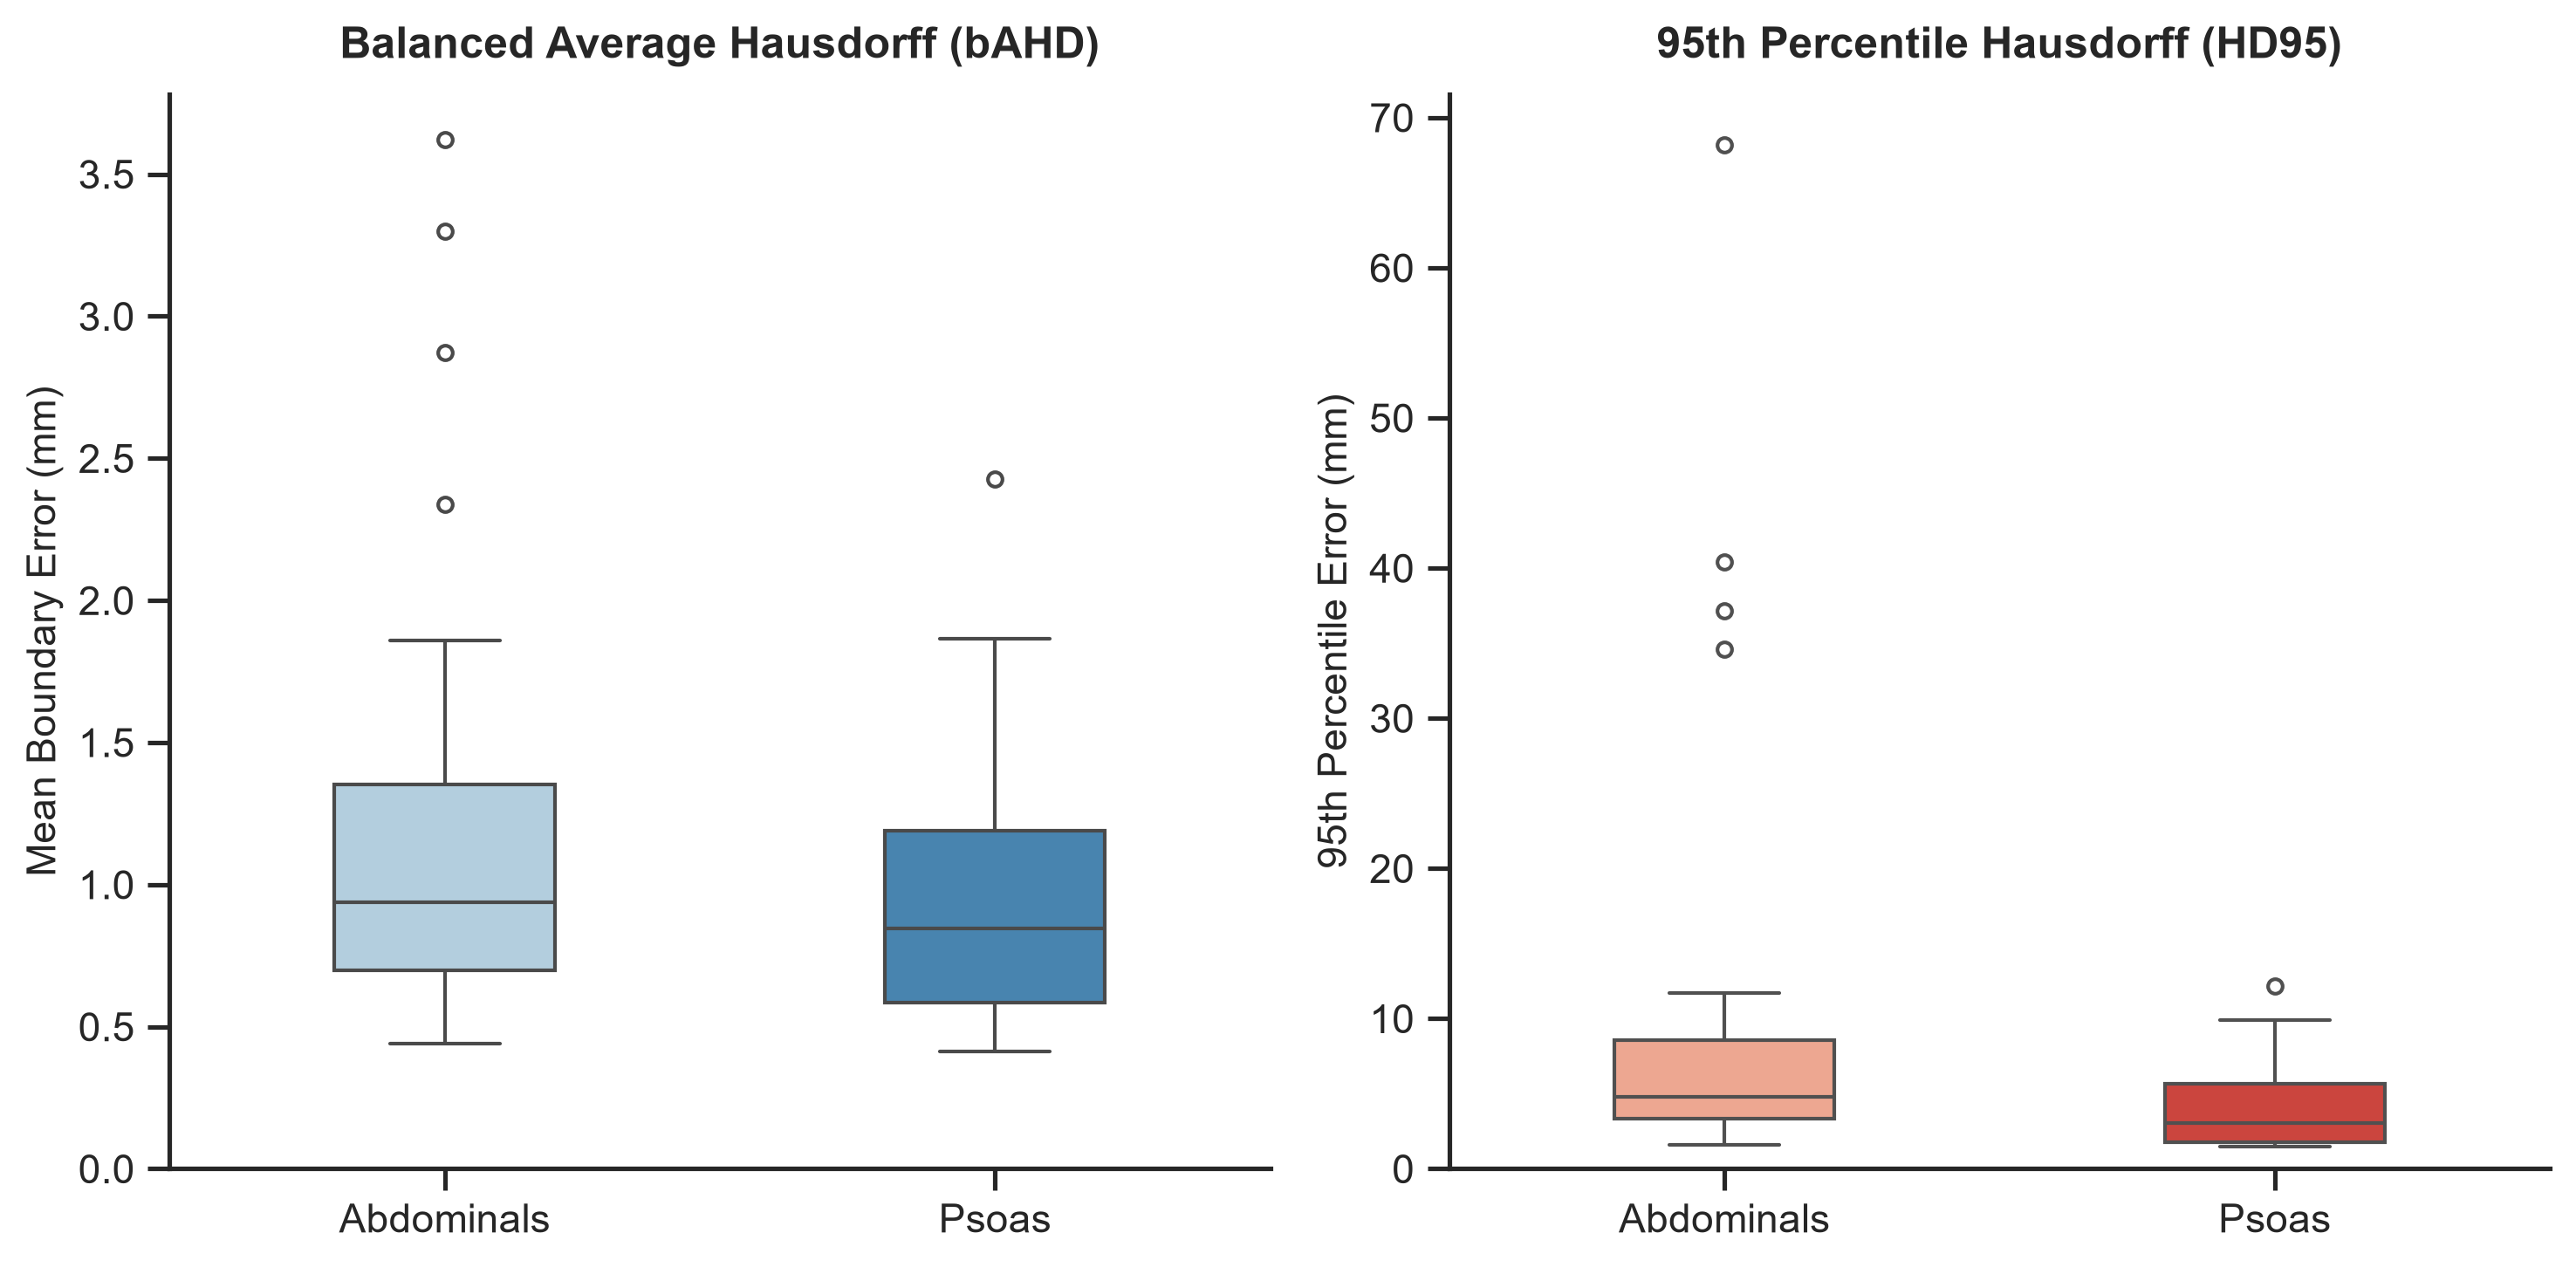

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def plot_boundary_error_distributions(abdominals_bahd, psoas_bahd, abdominals_hd95, psoas_hd95):
    print("\nGenerating Statistical Distribution Boxplots (Test Set)...")
    
    # Establish a clean, academic aesthetic for publication
    sns.set_theme(style="ticks")
    
    # Initialize figure architecture (1 row, 2 columns)
    fig, axes = plt.subplots(1, 2, figsize=(10, 5), dpi=300)
    fig.patch.set_facecolor('white') 
    
    # 1. Prepare and plot bAHD Data
    df_bahd = pd.DataFrame({
        'Abdominals': abdominals_bahd,
        'Psoas': psoas_bahd
    })
    
    sns.boxplot(data=df_bahd, ax=axes[0], width=0.4, palette="Blues", fliersize=4)
    axes[0].set_title('Balanced Average Hausdorff (bAHD)', fontsize=12, fontweight='bold', pad=10)
    axes[0].set_ylabel('Mean Boundary Error (mm)', fontsize=11)
    axes[0].set_ylim(bottom=0) 
    
    # 2. Prepare and plot HD95 Data
    df_hd95 = pd.DataFrame({
        'Abdominals': abdominals_hd95,
        'Psoas': psoas_hd95
    })
    
    sns.boxplot(data=df_hd95, ax=axes[1], width=0.4, palette="Reds", fliersize=4)
    axes[1].set_title('95th Percentile Hausdorff (HD95)', fontsize=12, fontweight='bold', pad=10)
    axes[1].set_ylabel('95th Percentile Error (mm)', fontsize=11)
    axes[1].set_ylim(bottom=0)
    
    sns.despine()
    
    plt.tight_layout()
    #plt.savefig("thesis_TestSet_Metrics_Distribution.png", bbox_inches='tight', facecolor='white')
    plt.show()

# Execute plot generation
plot_boundary_error_distributions(
    abdominals_bahd_scores, 
    psoas_bahd_scores, 
    abdominals_hd95_scores, 
    psoas_hd95_scores
)

## 7. Qualitative Visual Inspection Framework

Quantitative spatial metrics ($HD_{95}$, bAHD) provide a mathematical summary of boundary adherence, but they must be accompanied by qualitative visual inspections to confirm that the model's predictions align with clinical anatomical logic. 

To facilitate a high-resolution visual comparison, a dynamic bounding-box algorithm (`crop_to_body`) is introduced. This function isolates the anatomical region of interest by trimming the vast surrounding background areas (air, mapped near HU $\approx -1000$). The resulting visualization provides a direct, side-by-side assessment of the original Computed Tomography (CT) scan, the human-annotated Ground Truth, and the experimental U-Net prediction.


In [13]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
import numpy as np

def crop_to_body(ct_slice, mask_true, mask_pred, margin=30):
    """
    Dynamically crops the image to the patient's body contour by removing background air,
    enhancing the visualization of the target muscle groups.
    """
    body_pixels = ct_slice > 0.05 
    rows = np.any(body_pixels, axis=1)
    cols = np.any(body_pixels, axis=0)
    
    if not np.any(rows) or not np.any(cols):
        return ct_slice, mask_true, mask_pred 
        
    rmin, rmax = np.where(rows)[0][[0, -1]]
    cmin, cmax = np.where(cols)[0][[0, -1]]
    
    rmin, rmax = max(0, rmin-margin), min(ct_slice.shape[0], rmax+margin)
    cmin, cmax = max(0, cmin-margin), min(ct_slice.shape[1], cmax+margin)
    
    return ct_slice[rmin:rmax, cmin:cmax], mask_true[rmin:rmax, cmin:cmax], mask_pred[rmin:rmax, cmin:cmax]

def plot_step2_segmentation(ct_slice, true_mask, pred_mask, slice_idx=1):
    
    ct_slice = np.squeeze(ct_slice)
    true_mask = np.squeeze(true_mask)
    pred_mask = np.squeeze(pred_mask)
    
    ct_crop, true_crop, pred_crop = crop_to_body(ct_slice, true_mask, pred_mask)

    # Define strict colors: Background (None), Abdominals (Blue), Psoas (Green)
    cmap_masks = mcolors.ListedColormap(['none', '#1f77b4', '#2ca02c']) 
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 6), dpi=300)
    fig.patch.set_facecolor('white') 
    
    # 1. Original CT Scan
    axes[0].imshow(ct_crop, cmap='gray')
    axes[0].set_title('Original CT Scan', fontsize=14, pad=10)
    axes[0].axis('off')

    # 2. Ground Truth 
    axes[1].imshow(ct_crop, cmap='gray')
    mask_true_masked = np.ma.masked_where(true_crop == 0, true_crop)
    # vmin=0, vmax=2 strictly locks the color mapping to the 3 anatomical classes
    axes[1].imshow(mask_true_masked, cmap=cmap_masks, alpha=0.6, vmin=0, vmax=2)
    axes[1].set_title('Ground Truth (Clinical)', fontsize=14, pad=10)
    axes[1].axis('off')

    # 3. AI Prediction
    axes[2].imshow(ct_crop, cmap='gray')
    mask_pred_masked = np.ma.masked_where(pred_crop == 0, pred_crop)
    axes[2].imshow(mask_pred_masked, cmap=cmap_masks, alpha=0.6, vmin=0, vmax=2)
    axes[2].set_title('U-Net Prototype Prediction', fontsize=14, pad=10)
    axes[2].axis('off')

    legend_elements = [
        Patch(facecolor='#1f77b4', alpha=0.6, label='Abdominals (Class 1)'),
        Patch(facecolor='#2ca02c', alpha=0.6, label='Psoas (Class 2)')
    ]
    fig.legend(handles=legend_elements, loc='lower center', ncol=2, bbox_to_anchor=(0.5, 0.05), fontsize=12, frameon=False)

    plt.tight_layout(rect=[0, 0.12, 1, 1]) 
    #plt.savefig(f"thesis_TestSet_Segmentation_Slice{slice_idx}.png", bbox_inches='tight', facecolor='white')
    plt.show()

## 8. Morphological Validation on the Test Set

To demonstrate the baseline performance of the experimental prototype, random batches are extracted from the independent Test Generator. The batches are dynamically scanned to ensure the visualization of slices containing valid foreground targets (e.g., Abdominal muscle tissue).

best case scenario

Ricerca del miglior caso nell'Internal Test Set e calcolo metriche complete...

 MIGLIOR CASO INTERNAL (Batch: 0 | Slice: 2)
ADDOMINALI -> Dice: 0.9513 | IoU: 0.9072 | bAHD: 0.43 mm | HD95: 3.00 mm
PSOAS      -> Dice: 0.8754 | IoU: 0.7783 | bAHD: 1.16 mm | HD95: 7.58 mm


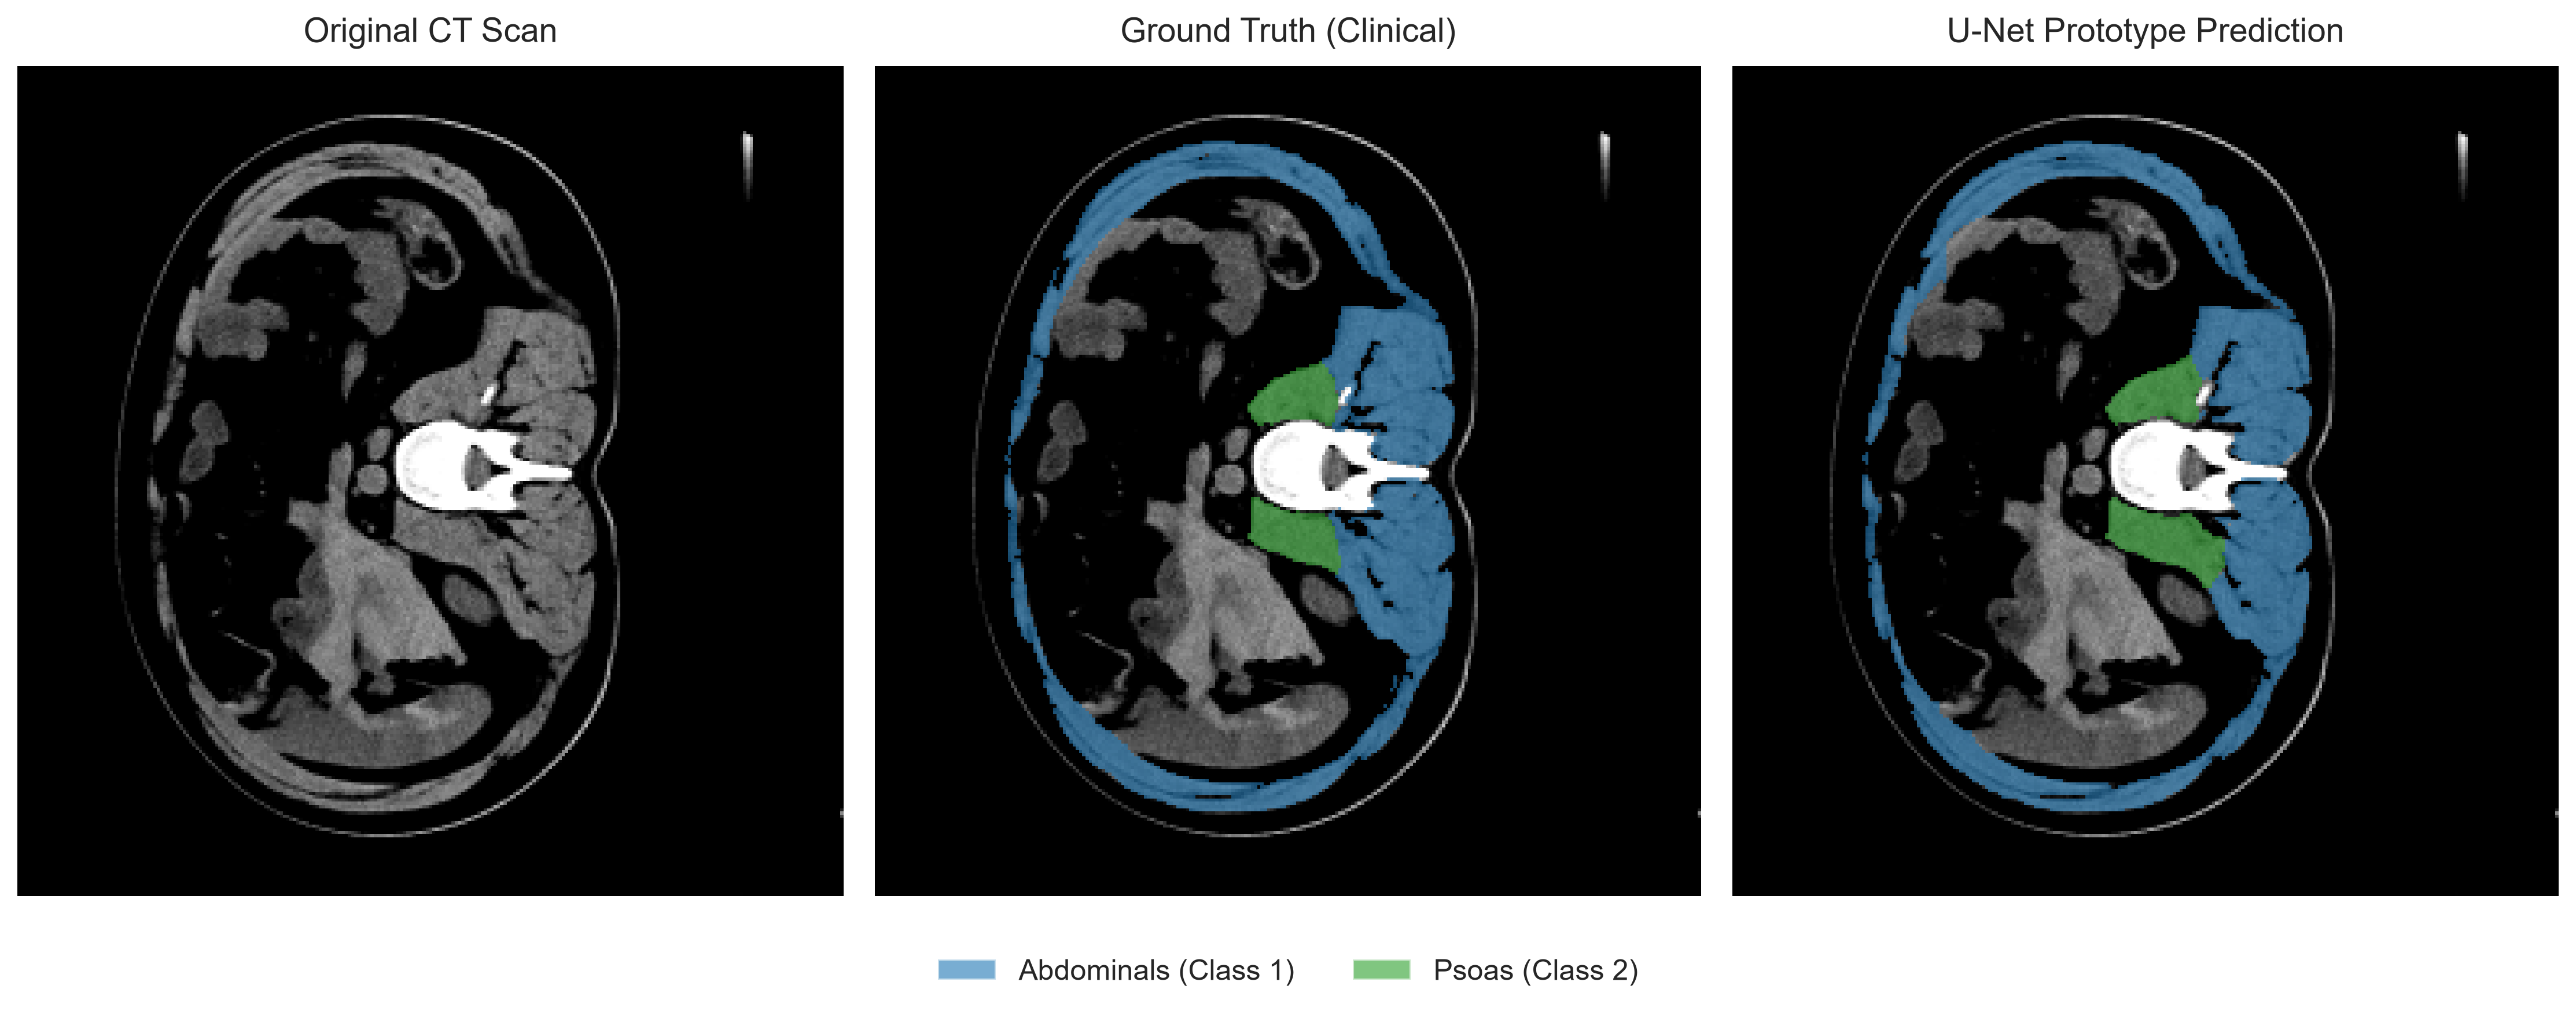

In [14]:
import numpy as np
import tensorflow as tf

print("Ricerca del miglior caso nell'Internal Test Set e calcolo metriche complete...")

migliori_casi_internal = []

# 1. Ricerca Veloce del Vincitore
for b in range(len(test_generator)):
    X_batch, y_batch = test_generator[b]
    preds_batch = model.predict(X_batch, verbose=0)
    pred_classes_batch = np.argmax(preds_batch, axis=-1)
    true_classes_batch = np.squeeze(y_batch, axis=-1)
    
    for i in range(X_batch.shape[0]):
        true_mask = true_classes_batch[i]
        pred_mask = pred_classes_batch[i]
        
        intersection = np.sum((true_mask > 0) & (pred_mask > 0))
        sum_masks = np.sum(true_mask > 0) + np.sum(pred_mask > 0)
        
        if sum_masks > 0:
            dice_score = (2.0 * intersection) / sum_masks
            migliori_casi_internal.append((dice_score, b, i, X_batch[i], true_mask, pred_mask))

migliori_casi_internal.sort(key=lambda x: x[0], reverse=True)
best_dice, best_b, best_i, best_img, best_true, best_pred = migliori_casi_internal[0]

# 2. Calcolo Metriche Dettagliate per il Vincitore
def calc_metrics_single_class(y_true, y_pred, class_val):
    t_mask = (y_true == class_val)
    p_mask = (y_pred == class_val)
    inter = np.sum(t_mask & p_mask)
    sum_m = np.sum(t_mask) + np.sum(p_mask)
    dice = (2.0 * inter) / sum_m if sum_m > 0 else 0
    iou = inter / (sum_m - inter) if (sum_m - inter) > 0 else 0
    # Assumiamo spaziatura 1.0mm per i tensori generati 256x256 se non hai i metadati originali qui
    bahd = calculate_bAHD_single_class_mm(t_mask, p_mask, 1.0, 1.0)
    hd95 = calculate_HD95_single_class_mm(t_mask, p_mask, 1.0, 1.0)
    return dice, iou, bahd, hd95

dice_abs, iou_abs, bahd_abs, hd95_abs = calc_metrics_single_class(best_true, best_pred, 1)
dice_psoas, iou_psoas, bahd_psoas, hd95_psoas = calc_metrics_single_class(best_true, best_pred, 2)

print("\n==================================================")
print(f" MIGLIOR CASO INTERNAL (Batch: {best_b} | Slice: {best_i})")
print("==================================================")
print(f"ADDOMINALI -> Dice: {dice_abs:.4f} | IoU: {iou_abs:.4f} | bAHD: {bahd_abs:.2f} mm | HD95: {hd95_abs:.2f} mm")
print(f"PSOAS      -> Dice: {dice_psoas:.4f} | IoU: {iou_psoas:.4f} | bAHD: {bahd_psoas:.2f} mm | HD95: {hd95_psoas:.2f} mm")
print("==================================================")

plot_step2_segmentation(
    ct_slice=best_img, 
    true_mask=best_true, 
    pred_mask=best_pred, 
    slice_idx=f"BestInternal_Dice{best_dice:.2f}" 
)

Ricerca del miglior caso nell'Internal Test Set e calcolo metriche complete...

 MIGLIOR CASO INTERNAL (File: slice_subject_126.nii)
ADDOMINALI -> Dice: 0.9513 | IoU: 0.9072 | bAHD: 0.43 mm | HD95: 3.00 mm
PSOAS      -> Dice: 0.8754 | IoU: 0.7783 | bAHD: 1.16 mm | HD95: 7.58 mm


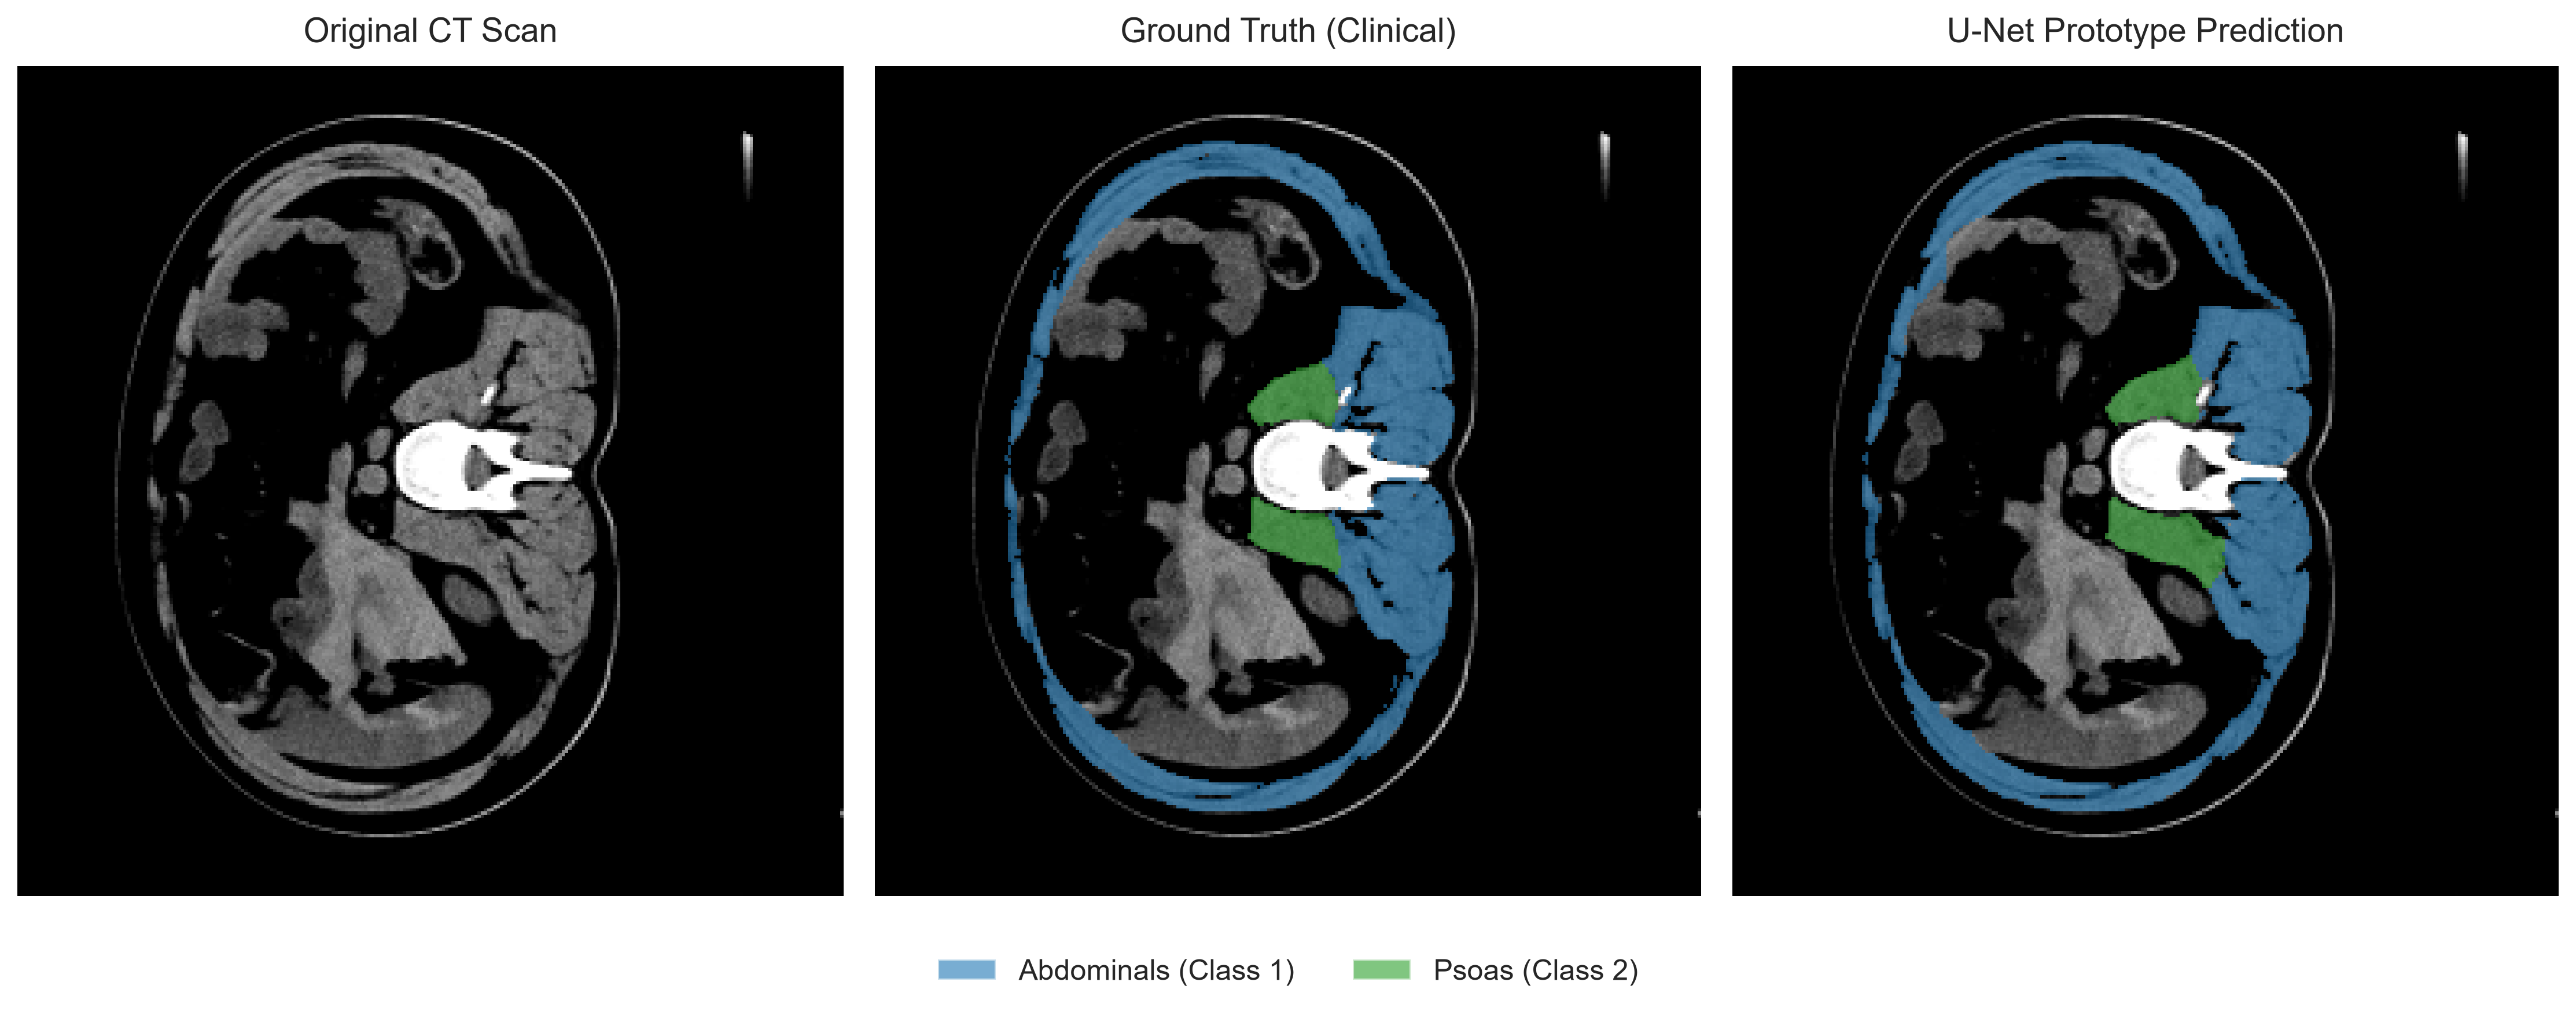

In [15]:
import numpy as np
import tensorflow as tf

print("Ricerca del miglior caso nell'Internal Test Set e calcolo metriche complete...")

migliori_casi_internal = []
batch_size = test_generator.batch_size

# 1. Ricerca Veloce del Vincitore
for b in range(len(test_generator)):
    X_batch, y_batch = test_generator[b]
    preds_batch = model.predict(X_batch, verbose=0)
    pred_classes_batch = np.argmax(preds_batch, axis=-1)
    true_classes_batch = np.squeeze(y_batch, axis=-1)
    
    # Estraiamo i percorsi originali per questo specifico batch
    batch_paths = test_img[b * batch_size : (b + 1) * batch_size]

    for i in range(X_batch.shape[0]):
        true_mask = true_classes_batch[i]
        pred_mask = pred_classes_batch[i]

        intersection = np.sum((true_mask > 0) & (pred_mask > 0))
        sum_masks = np.sum(true_mask > 0) + np.sum(pred_mask > 0)

        if sum_masks > 0:
            dice_score = (2.0 * intersection) / sum_masks
            # Aggiungiamo batch_paths[i] (il percorso del file) alla tupla
            migliori_casi_internal.append((dice_score, batch_paths[i], X_batch[i], true_mask, pred_mask))

migliori_casi_internal.sort(key=lambda x: x[0], reverse=True)
# Estraiamo il file path al posto di best_b e best_i
best_dice, best_filepath, best_img, best_true, best_pred = migliori_casi_internal[0]

# Estraiamo solo il nome del file dal percorso completo
file_name = best_filepath.name if hasattr(best_filepath, 'name') else str(best_filepath).replace('\\', '/').split('/')[-1]

# 2. Calcolo Metriche Dettagliate per il Vincitore
def calc_metrics_single_class(y_true, y_pred, class_val):
    t_mask = (y_true == class_val)
    p_mask = (y_pred == class_val)
    inter = np.sum(t_mask & p_mask)
    sum_m = np.sum(t_mask) + np.sum(p_mask)
    dice = (2.0 * inter) / sum_m if sum_m > 0 else 0
    iou = inter / (sum_m - inter) if (sum_m - inter) > 0 else 0
    # Assumiamo spaziatura 1.0mm per i tensori generati 256x256 se non hai i metadati originali qui
    bahd = calculate_bAHD_single_class_mm(t_mask, p_mask, 1.0, 1.0)
    hd95 = calculate_HD95_single_class_mm(t_mask, p_mask, 1.0, 1.0)
    return dice, iou, bahd, hd95

dice_abs, iou_abs, bahd_abs, hd95_abs = calc_metrics_single_class(best_true, best_pred, 1)
dice_psoas, iou_psoas, bahd_psoas, hd95_psoas = calc_metrics_single_class(best_true, best_pred, 2)

print("\n==================================================")
# Ora stampa il nome effettivo del file!
print(f" MIGLIOR CASO INTERNAL (File: {file_name})")
print("==================================================")
print(f"ADDOMINALI -> Dice: {dice_abs:.4f} | IoU: {iou_abs:.4f} | bAHD: {bahd_abs:.2f} mm | HD95: {hd95_abs:.2f} mm")
print(f"PSOAS      -> Dice: {dice_psoas:.4f} | IoU: {iou_psoas:.4f} | bAHD: {bahd_psoas:.2f} mm | HD95: {hd95_psoas:.2f} mm")
print("==================================================")

plot_step2_segmentation(
    ct_slice=best_img, 
    true_mask=best_true, 
    pred_mask=best_pred, 
    slice_idx=f"BestInternal_{file_name.replace('.nii','')}_Dice{best_dice:.2f}" 
)

worst case scenario

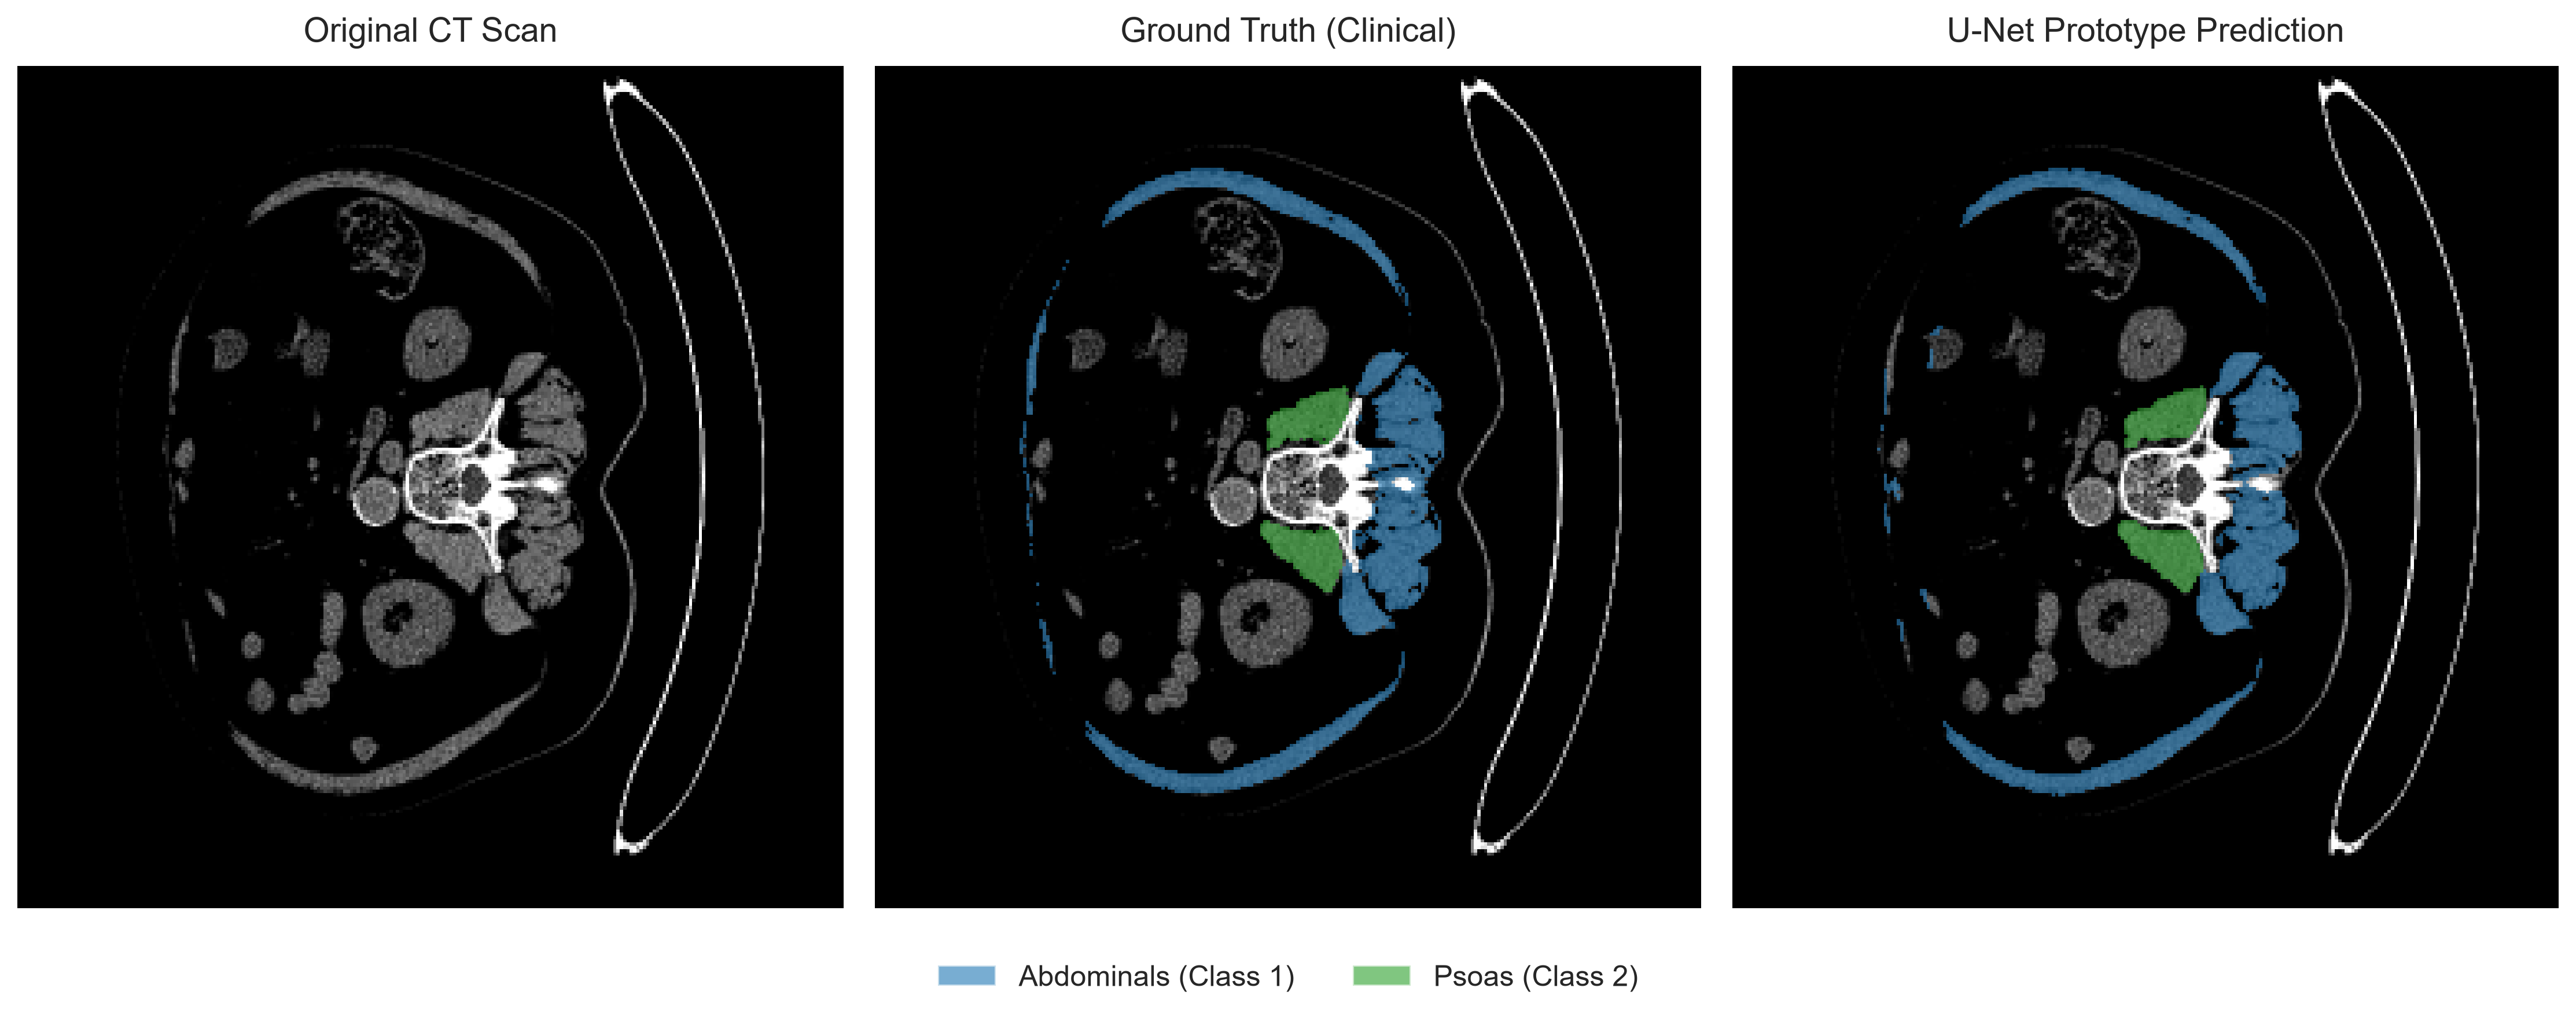

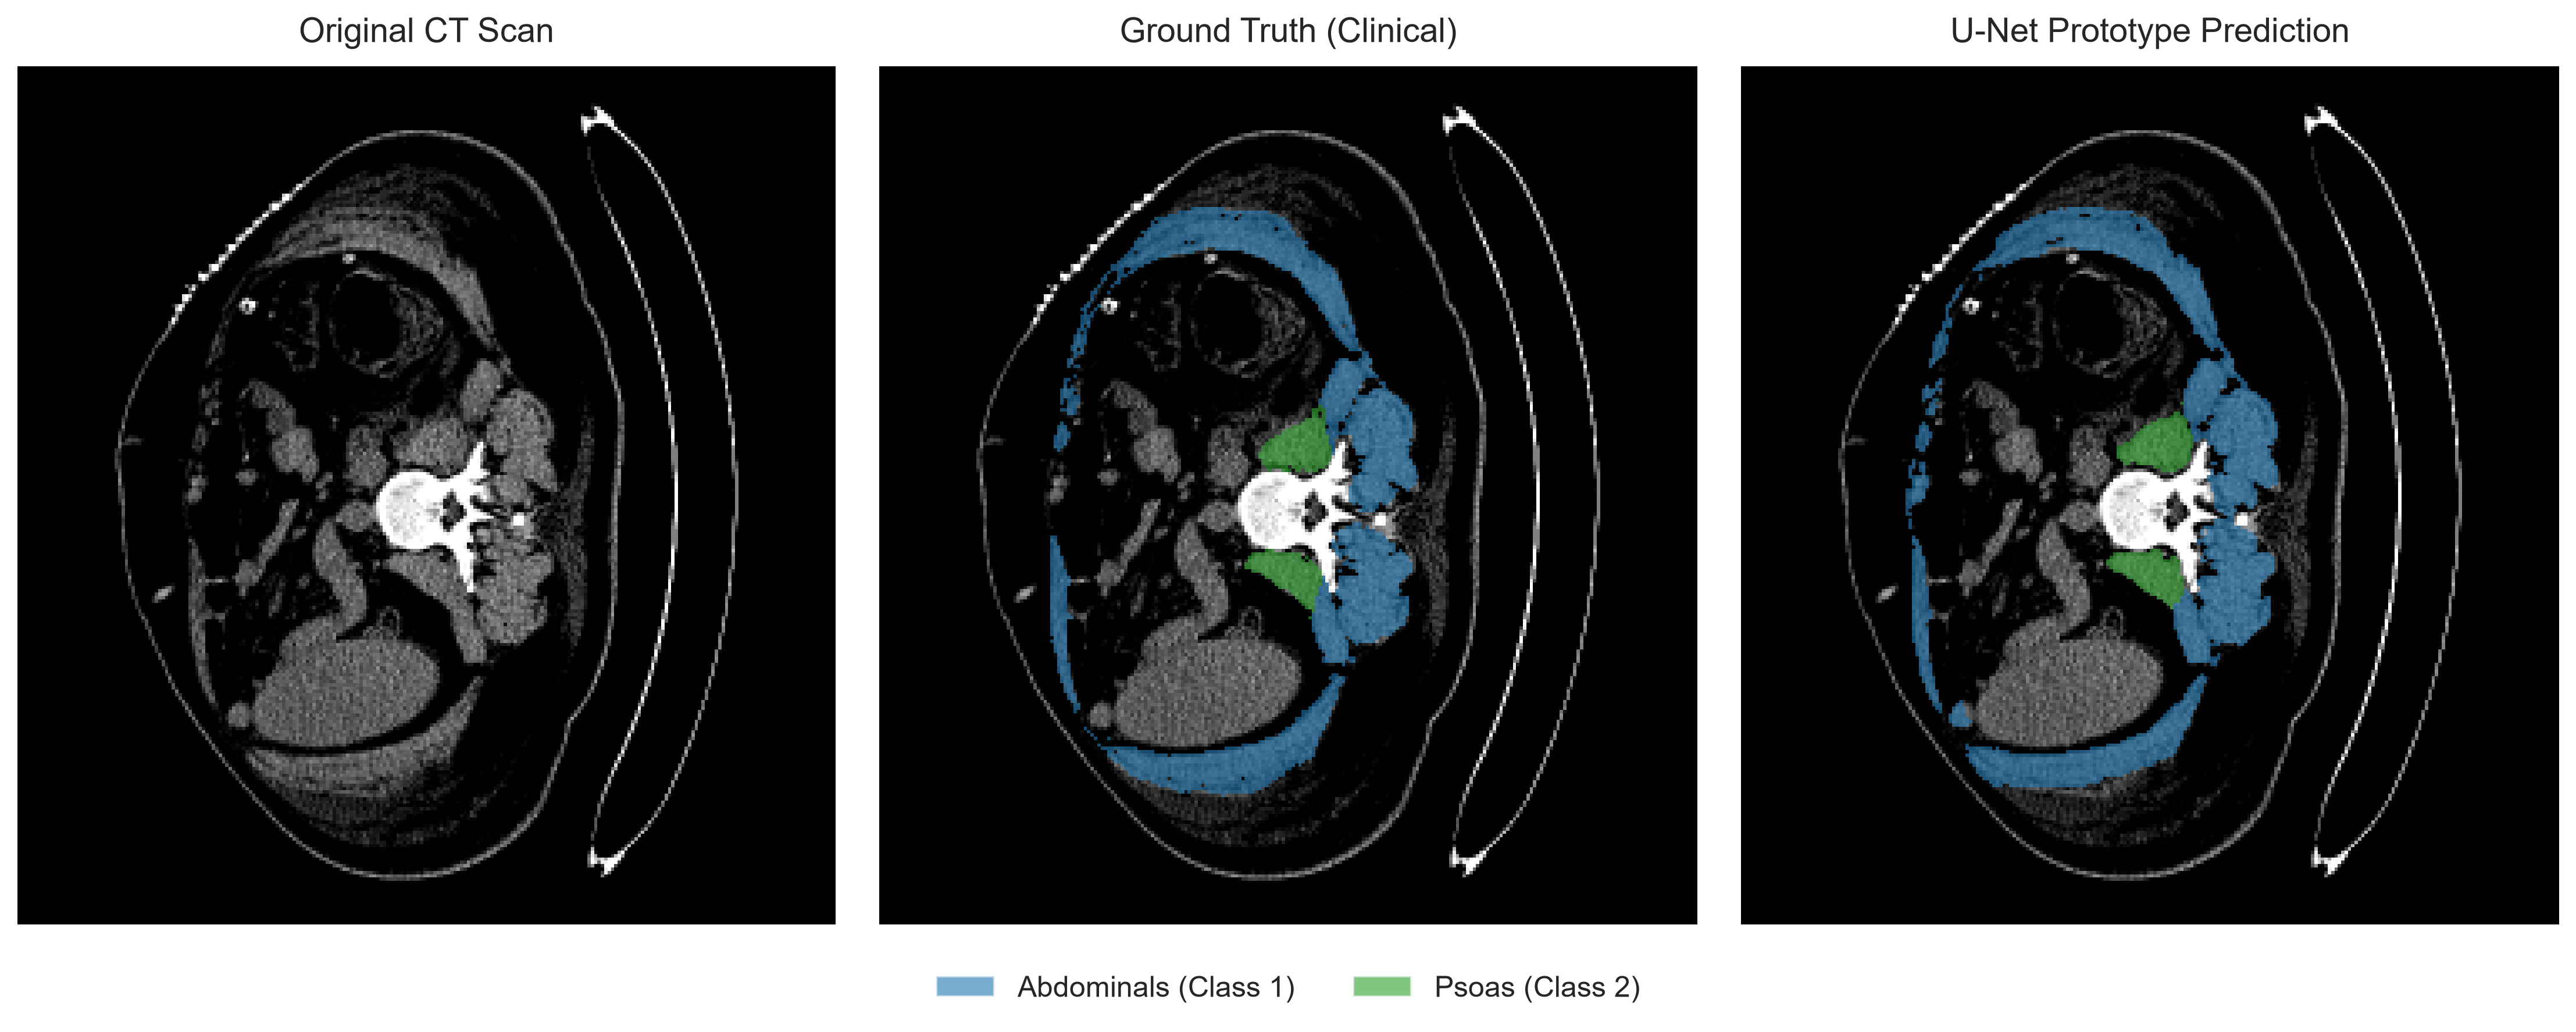

In [16]:
# --- Extraction 1 (Test Set) ---
X_test_batch, y_test_batch = test_generator[0]

preds_batch = model.predict(X_test_batch, verbose=0)
pred_classes_batch = np.argmax(preds_batch, axis=-1)

# Dynamically locate a slice containing Class 1 (Abdominals)
idx_scelto = 0
for i in range(X_test_batch.shape[0]):
    if np.any(y_test_batch[i] == 1): 
        idx_scelto = i
        break

plot_step2_segmentation(
    ct_slice=X_test_batch[idx_scelto], 
    true_mask=y_test_batch[idx_scelto], 
    pred_mask=pred_classes_batch[idx_scelto], 
    slice_idx=f"TestBatch0_Idx{idx_scelto}" 
)

# --- Extraction 2 (Test Set) ---
X_test_batch, y_test_batch = test_generator[1]

preds_batch = model.predict(X_test_batch, verbose=0)
pred_classes_batch = np.argmax(preds_batch, axis=-1)

idx_scelto = 0
for i in range(X_test_batch.shape[0]):
    if np.any(y_test_batch[i] == 1):
        idx_scelto = i
        break

plot_step2_segmentation(
    ct_slice=X_test_batch[idx_scelto], 
    true_mask=y_test_batch[idx_scelto], 
    pred_mask=pred_classes_batch[idx_scelto], 
    slice_idx=f"TestBatch1_Idx{idx_scelto}" 
)

## 9. Clinical Auditing: The Worst-Case Scenario

A scientifically rigorous model evaluation must actively investigate its own limitations. In this final auditing step, the entire Test Set is iterated to isolate the single prediction exhibiting the highest 95th Percentile Hausdorff Distance ($HD_{95}$) error in physical millimeters.

Extracting and plotting this "Worst-Case Scenario" allows for critical error analysis. It determines whether the maximum mathematical error is driven by a severe morphological failure (e.g., completely misidentifying the abdominal wall shape) or an isolated artifact classification (e.g., segmenting a section of intestinal tissue or arm muscle), which could theoretically be mitigated through standard connected-component post-processing in a future clinical pipeline.

Ricerca del PEGGIOR CASO (Max HD95) nell'Internal Test Set e calcolo metriche complete...

 PEGGIOR CASO INTERNAL (File: slice_subject_116.nii | Batch: 6 | Slice: 1)
ADDOMINALI -> Dice: 0.9162 | IoU: 0.8453 | bAHD: 2.87 mm | HD95: 68.22 mm
PSOAS      -> Dice: 0.9382 | IoU: 0.8835 | bAHD: 0.72 mm | HD95: 3.16 mm


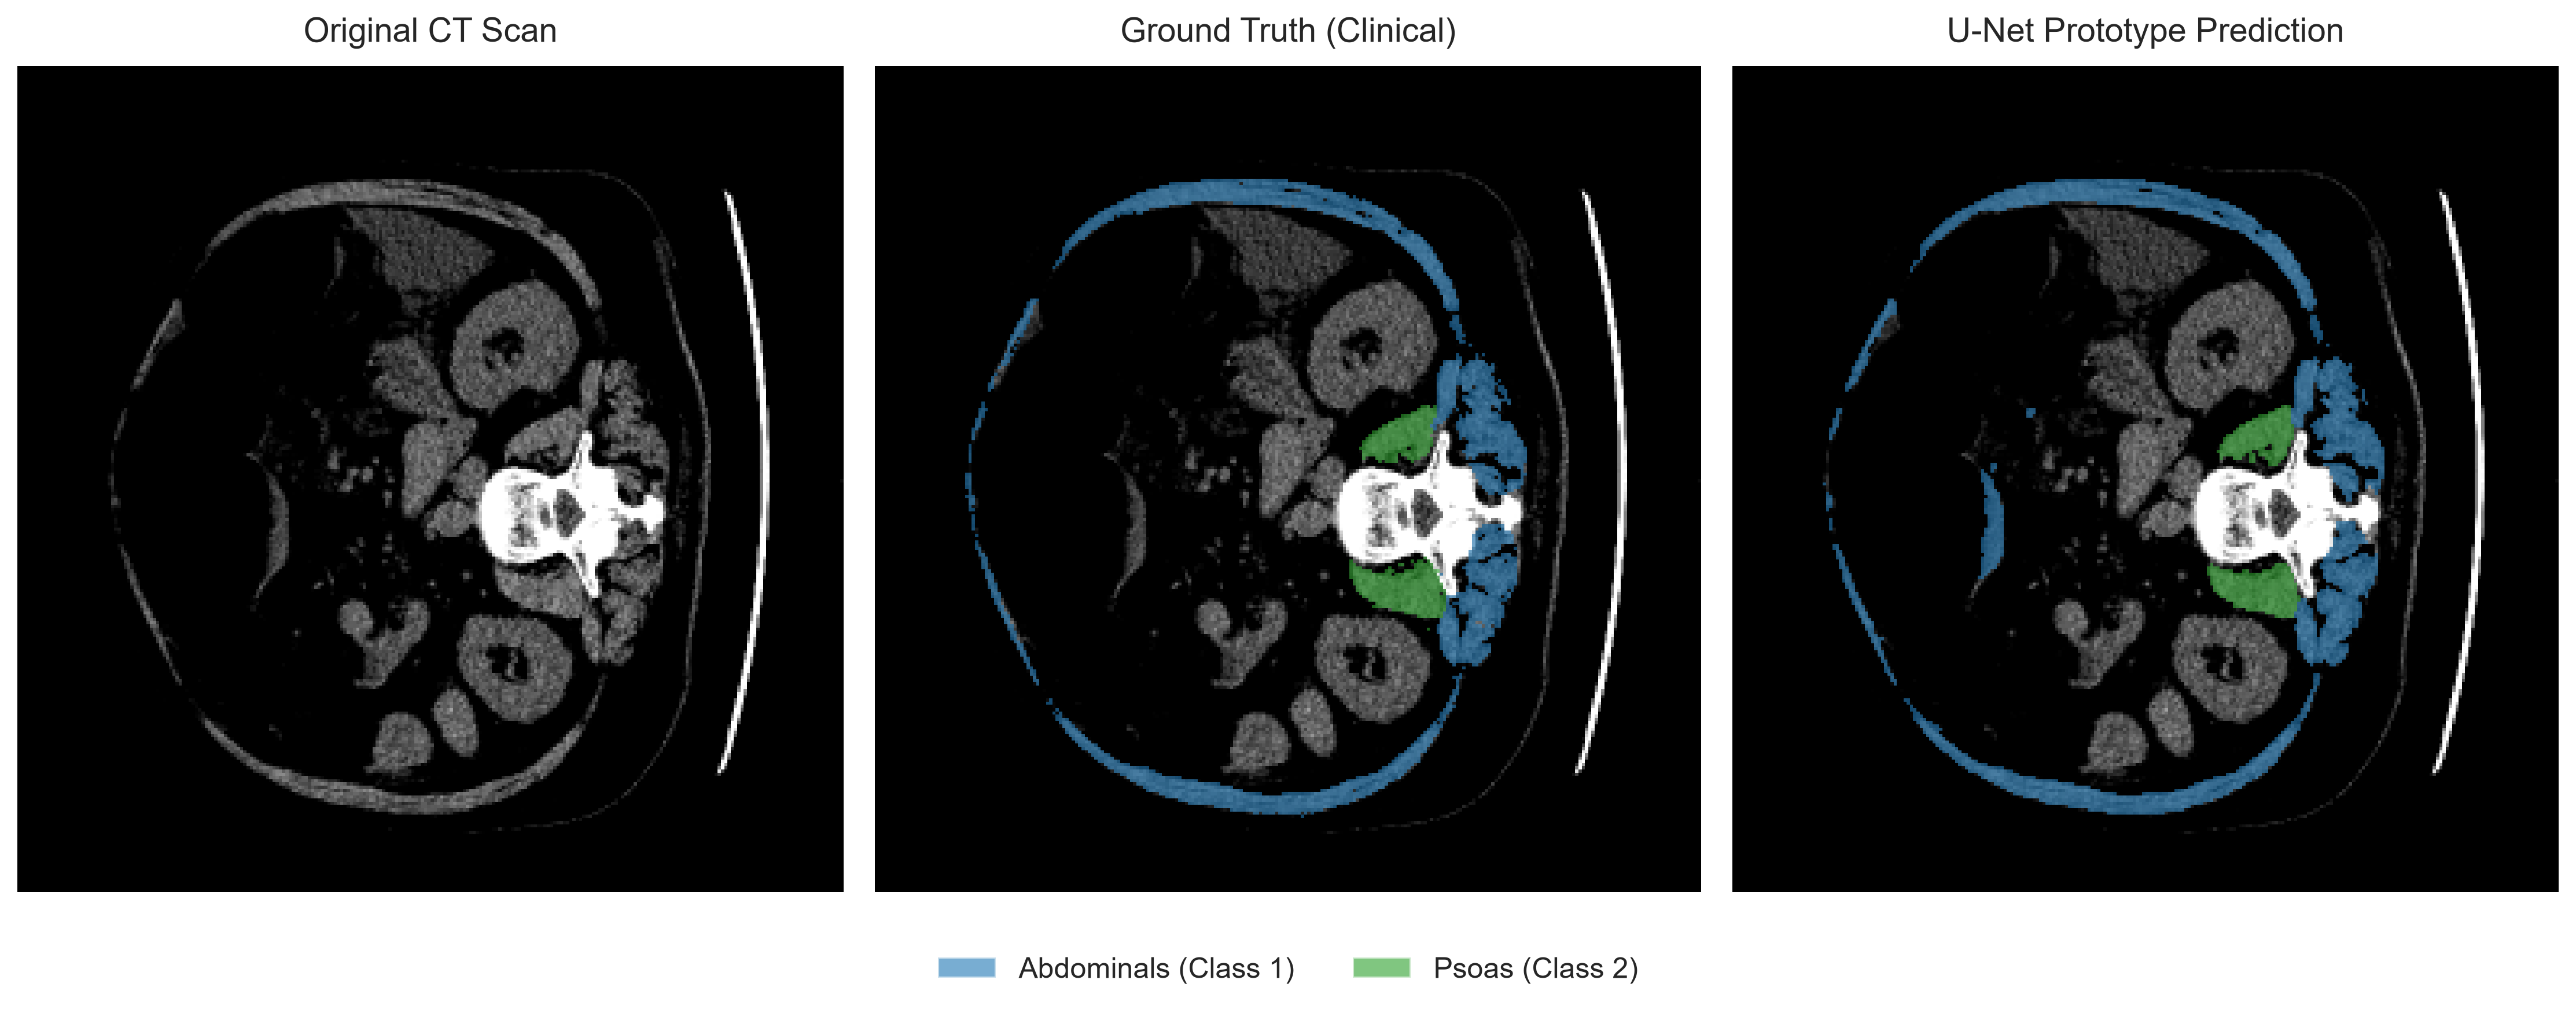

In [17]:
import numpy as np
import nibabel as nib
import tensorflow as tf

print("Ricerca del PEGGIOR CASO (Max HD95) nell'Internal Test Set e calcolo metriche complete...")

worst_hd95_mm = 0.0
worst_data = None 

TARGET_SIZE = 256
batch_size = test_generator.batch_size

# 1. Scansione alla ricerca del peggiore
for i in range(len(test_generator)):
    X_batch, y_batch = test_generator[i]
    preds = model.predict(X_batch, verbose=0)
    pred_classes = np.argmax(preds, axis=-1)
    true_classes = np.squeeze(y_batch, axis=-1) 

    batch_paths = test_img[i * batch_size : (i + 1) * batch_size]

    for j in range(X_batch.shape[0]):
        true_mask = true_classes[j]
        pred_mask = pred_classes[j]
        
        nii_file = nib.load(batch_paths[j])
        original_zooms = nii_file.header.get_zooms()
        original_shape = nii_file.shape
        
        spacing_x_mm = original_zooms[0] * (original_shape[0] / TARGET_SIZE)
        spacing_y_mm = original_zooms[1] * (original_shape[1] / TARGET_SIZE)

        # Audit sia Addominali che Psoas
        hd95_abs = calculate_HD95_single_class_mm(true_mask == 1, pred_mask == 1, spacing_y_mm, spacing_x_mm)
        hd95_psoas = calculate_HD95_single_class_mm(true_mask == 2, pred_mask == 2, spacing_y_mm, spacing_x_mm)
        
        val_abs = hd95_abs if not np.isnan(hd95_abs) else 0.0
        val_psoas = hd95_psoas if not np.isnan(hd95_psoas) else 0.0
        
        max_hd95 = max(val_abs, val_psoas)
        
        # Salviamo il record se è il peggiore finora
        if max_hd95 > worst_hd95_mm:
            worst_hd95_mm = max_hd95
            worst_data = (i, j, X_batch[j], true_mask, pred_mask, spacing_y_mm, spacing_x_mm, batch_paths[j])

# 2. Estrazione e Calcolo Metriche
best_b, best_i, best_img, best_true, best_pred, sp_y, sp_x, filepath = worst_data

def calc_metrics_single_class(y_true, y_pred, class_val, spacing_y, spacing_x):
    t_mask = (y_true == class_val)
    p_mask = (y_pred == class_val)
    inter = np.sum(t_mask & p_mask)
    sum_m = np.sum(t_mask) + np.sum(p_mask)
    dice = (2.0 * inter) / sum_m if sum_m > 0 else 0
    iou = inter / (sum_m - inter) if (sum_m - inter) > 0 else 0
    bahd = calculate_bAHD_single_class_mm(t_mask, p_mask, spacing_y, spacing_x)
    hd95 = calculate_HD95_single_class_mm(t_mask, p_mask, spacing_y, spacing_x)
    return dice, iou, bahd, hd95

dice_abs, iou_abs, bahd_abs, hd95_abs = calc_metrics_single_class(best_true, best_pred, 1, sp_y, sp_x)
dice_psoas, iou_psoas, bahd_psoas, hd95_psoas = calc_metrics_single_class(best_true, best_pred, 2, sp_y, sp_x)

print("\n==================================================")
print(f" PEGGIOR CASO INTERNAL (File: {filepath.name} | Batch: {best_b} | Slice: {best_i})")
print("==================================================")
print(f"ADDOMINALI -> Dice: {dice_abs:.4f} | IoU: {iou_abs:.4f} | bAHD: {bahd_abs:.2f} mm | HD95: {hd95_abs:.2f} mm")
print(f"PSOAS      -> Dice: {dice_psoas:.4f} | IoU: {iou_psoas:.4f} | bAHD: {bahd_psoas:.2f} mm | HD95: {hd95_psoas:.2f} mm")
print("==================================================")

plot_step2_segmentation(
    ct_slice=best_img, 
    true_mask=best_true, 
    pred_mask=best_pred, 
    slice_idx=f"WorstInternal_HD95_{worst_hd95_mm:.1f}mm" 
)

best and worst for HD95

Ricerca del MIGLIORE e PEGGIOR caso basati su HD95 nell'Internal Test Set...

 IL MIGLIORE CASO INTERNAL (File: slice_subject_72.nii)
ADDOMINALI -> Dice: 0.9654 | IoU: 0.9332 | bAHD: 0.48 mm | HD95: 1.76 mm
PSOAS      -> Dice: 0.9509 | IoU: 0.9063 | bAHD: 0.55 mm | HD95: 1.76 mm


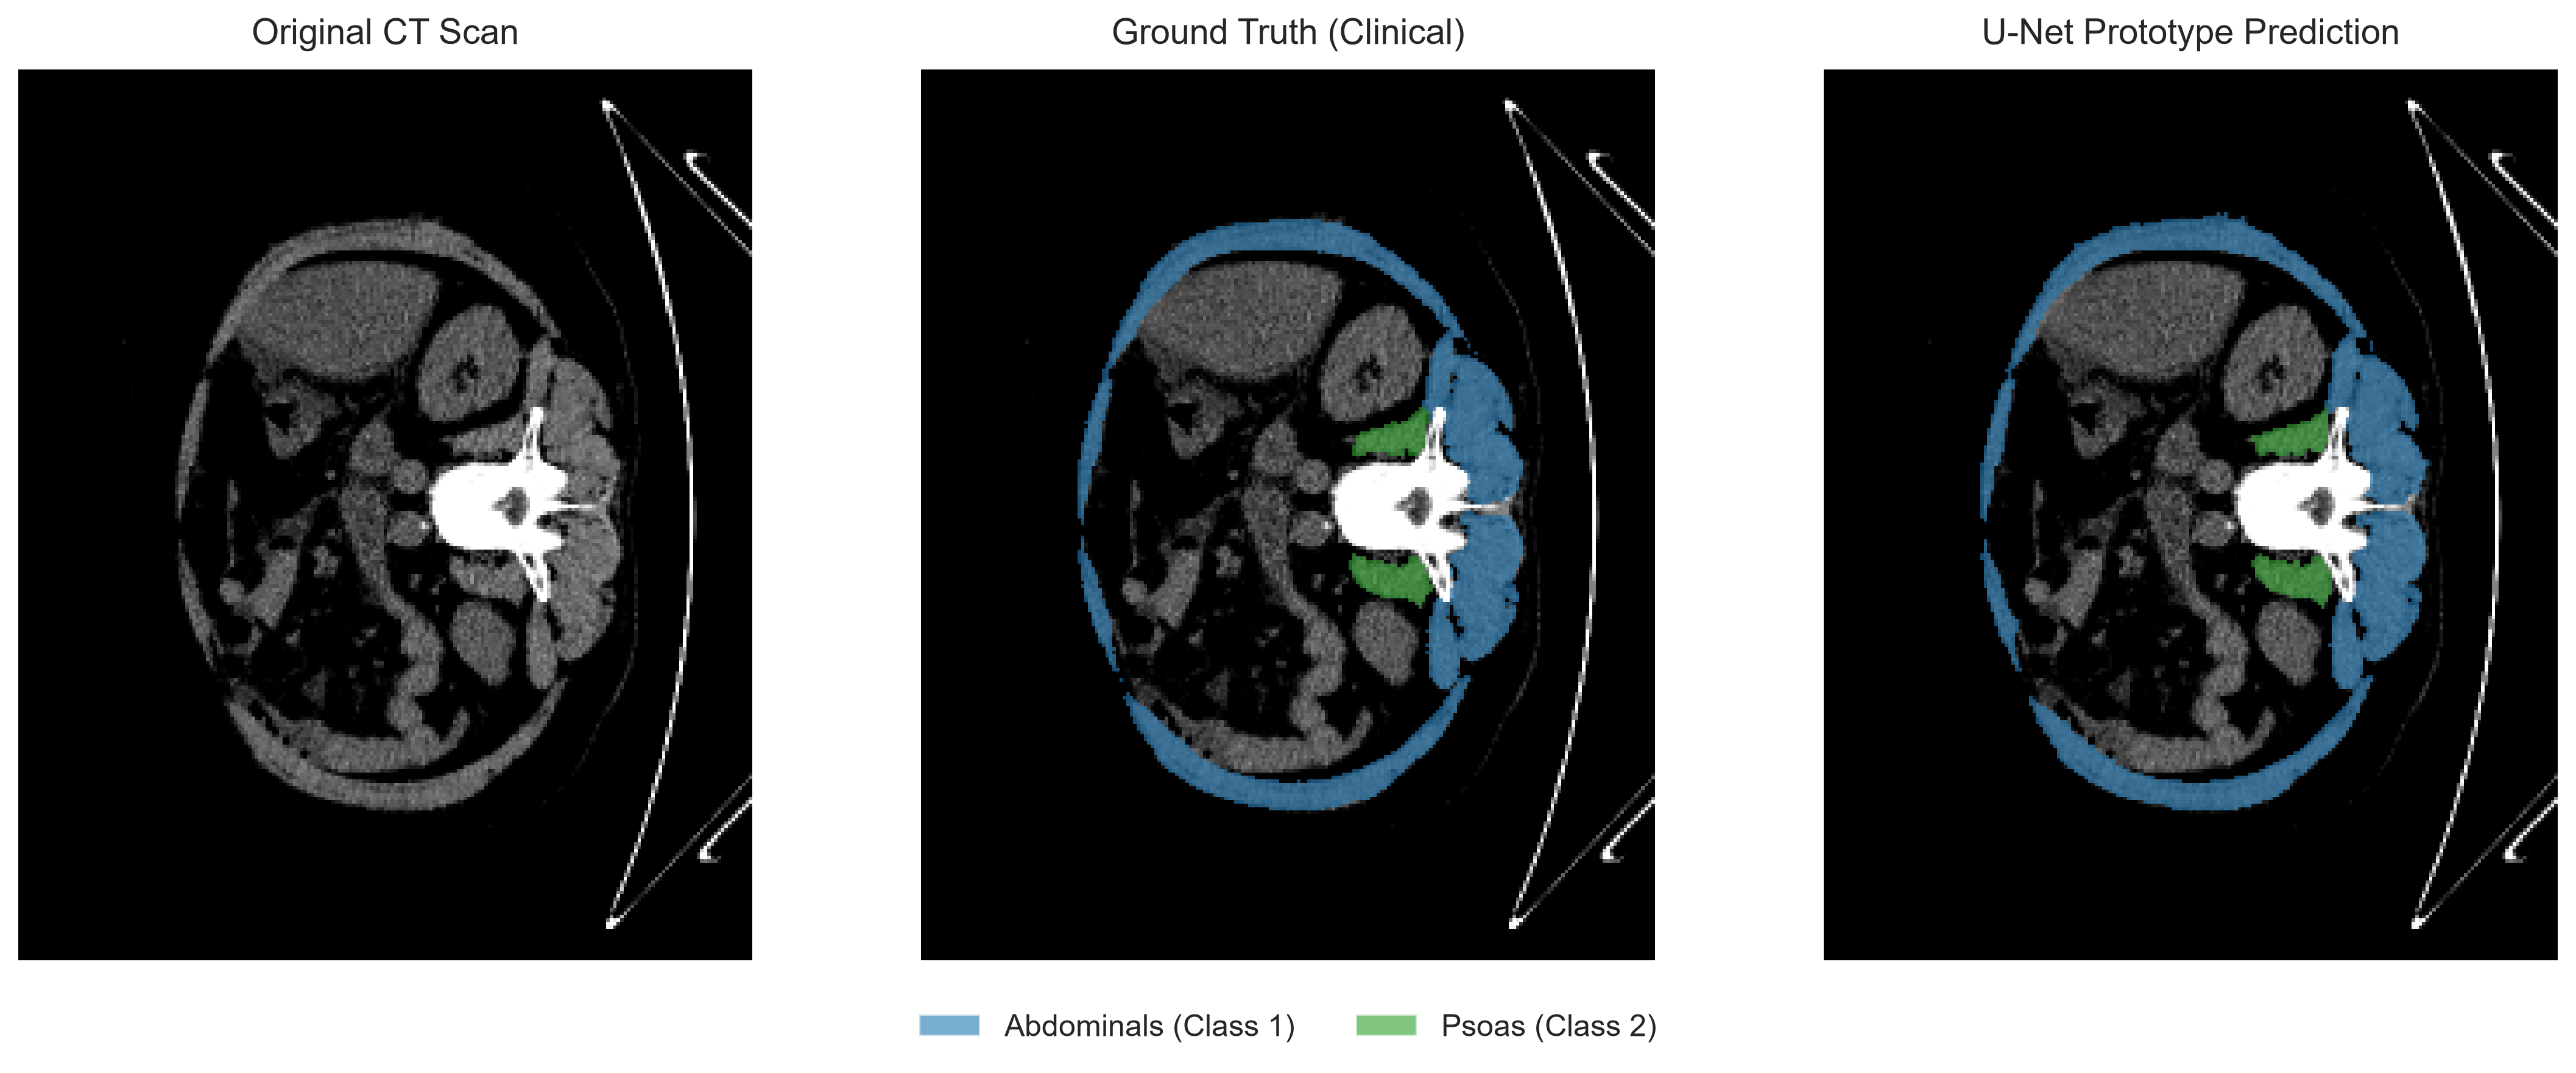


 IL PEGGIORE CASO INTERNAL (File: slice_subject_116.nii)
ADDOMINALI -> Dice: 0.9162 | IoU: 0.8453 | bAHD: 2.87 mm | HD95: 68.22 mm
PSOAS      -> Dice: 0.9382 | IoU: 0.8835 | bAHD: 0.72 mm | HD95: 3.16 mm


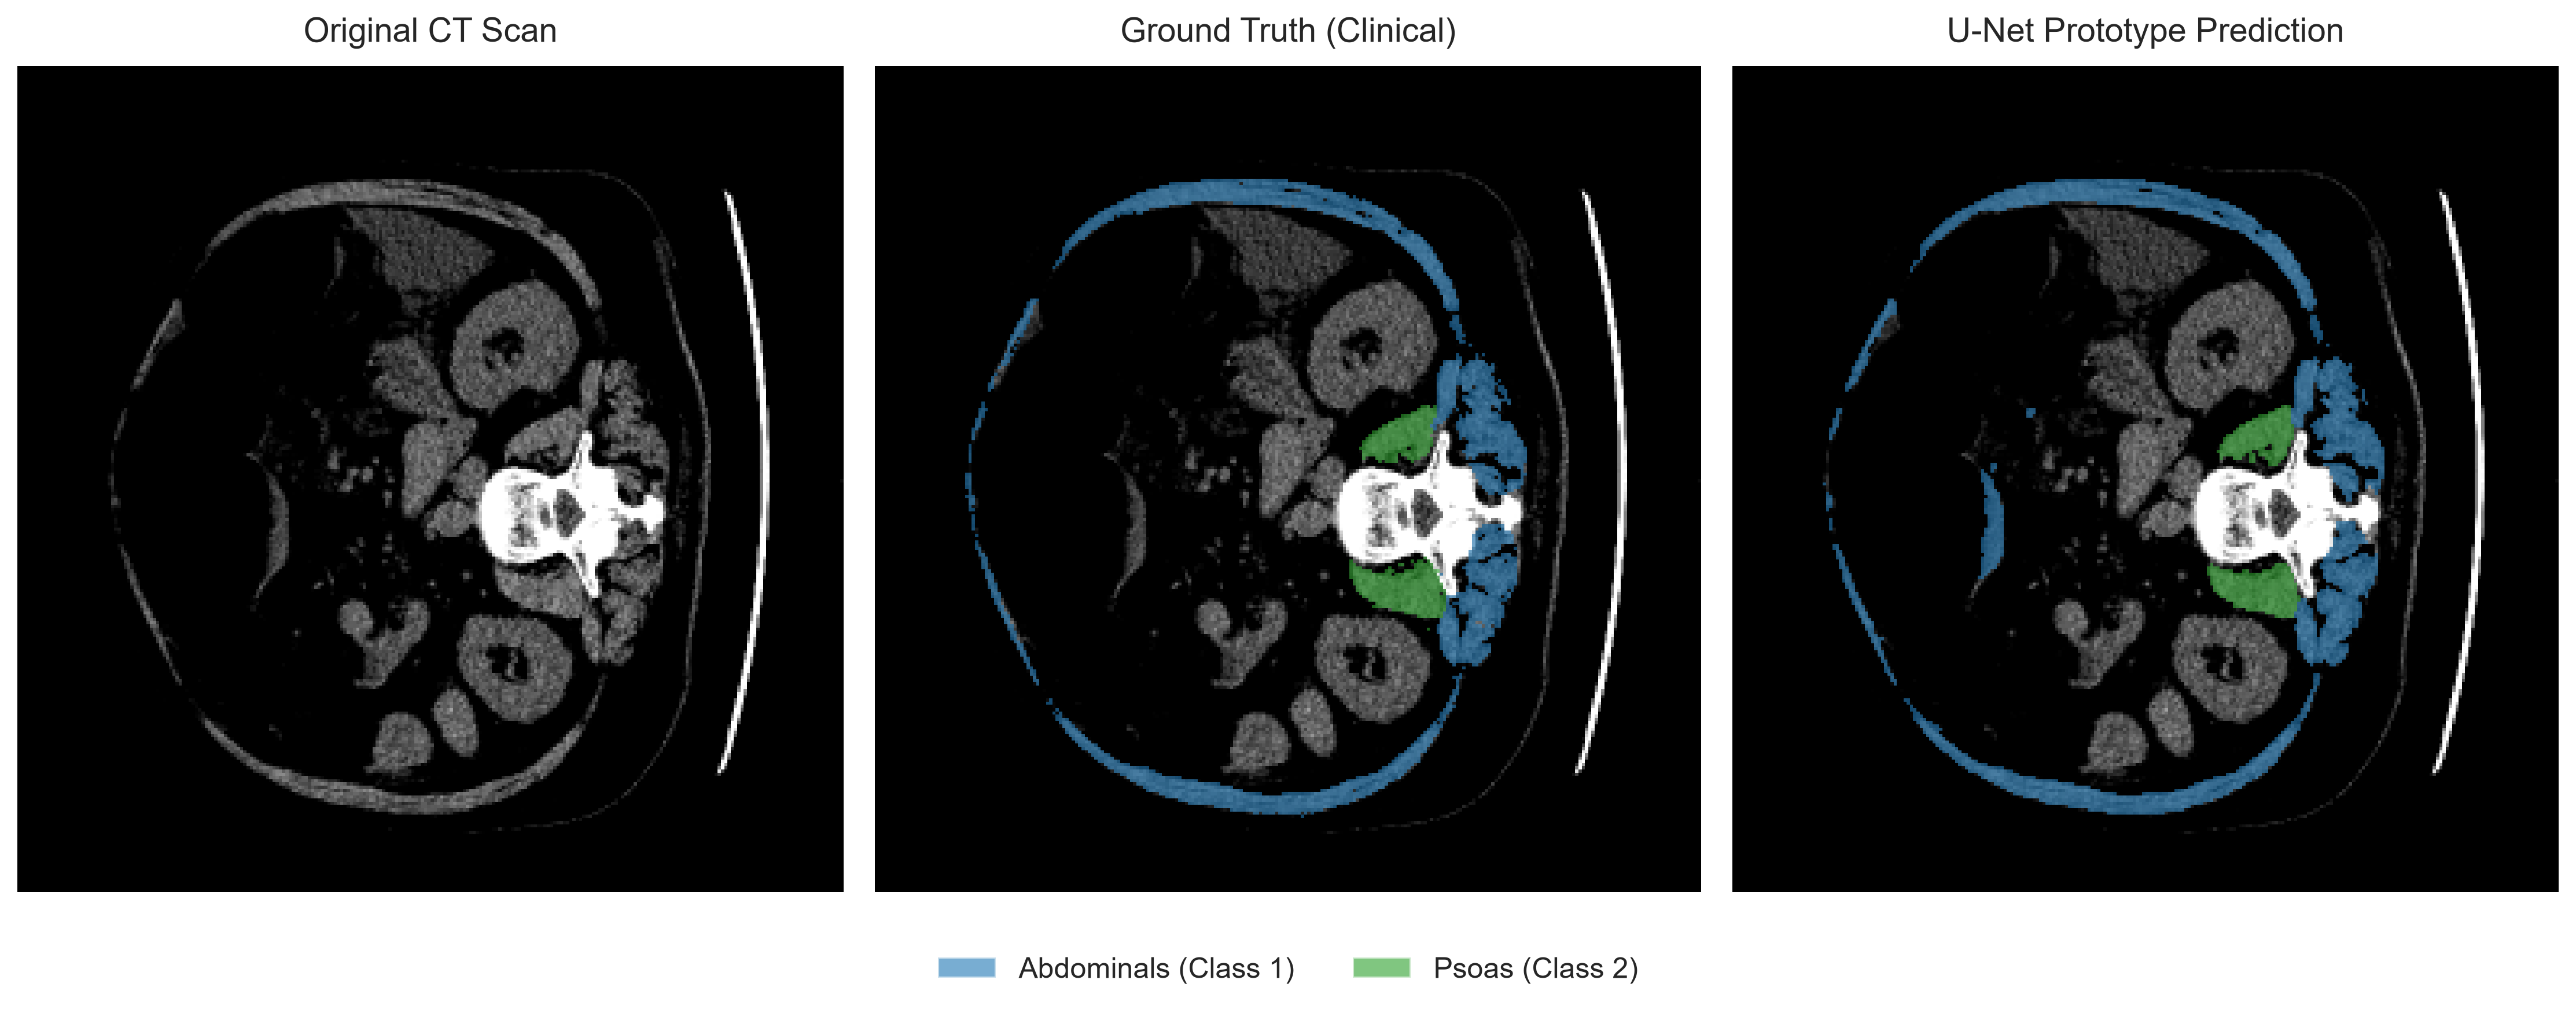

In [18]:
import numpy as np
import nibabel as nib
import tensorflow as tf

print("Ricerca del MIGLIORE e PEGGIOR caso basati su HD95 nell'Internal Test Set...")

classifica_internal = []
TARGET_SIZE = 256
batch_size = test_generator.batch_size

def calc_all_metrics(y_true, y_pred, class_val, spacing_y, spacing_x):
    t_mask = (y_true == class_val)
    p_mask = (y_pred == class_val)
    inter = np.sum(t_mask & p_mask)
    sum_m = np.sum(t_mask) + np.sum(p_mask)
    dice = (2.0 * inter) / sum_m if sum_m > 0 else 0
    iou = inter / (sum_m - inter) if (sum_m - inter) > 0 else 0
    bahd = calculate_bAHD_single_class_mm(t_mask, p_mask, spacing_y, spacing_x)
    hd95 = calculate_HD95_single_class_mm(t_mask, p_mask, spacing_y, spacing_x)
    return dice, iou, bahd, hd95

# 1. Scansione di tutto il Test Set
for i in range(len(test_generator)):
    X_batch, y_batch = test_generator[i]
    preds = model.predict(X_batch, verbose=0)
    pred_classes = np.argmax(preds, axis=-1)
    true_classes = np.squeeze(y_batch, axis=-1) 

    batch_paths = test_img[i * batch_size : (i + 1) * batch_size]

    for j in range(X_batch.shape[0]):
        true_mask = true_classes[j]
        pred_mask = pred_classes[j]
        
        nii_file = nib.load(batch_paths[j])
        original_zooms = nii_file.header.get_zooms()
        original_shape = nii_file.shape
        
        spacing_x_mm = original_zooms[0] * (original_shape[0] / TARGET_SIZE)
        spacing_y_mm = original_zooms[1] * (original_shape[1] / TARGET_SIZE)

        # Calcoliamo HD95
        hd95_abs = calculate_HD95_single_class_mm(true_mask == 1, pred_mask == 1, spacing_y_mm, spacing_x_mm)
        hd95_psoas = calculate_HD95_single_class_mm(true_mask == 2, pred_mask == 2, spacing_y_mm, spacing_x_mm)
        
        # Saltiamo le slice vuote (dove HD95 è nan o 0)
        if np.isnan(hd95_abs) or np.isnan(hd95_psoas) or (hd95_abs == 0 and hd95_psoas == 0):
            continue
            
        max_hd95 = max(hd95_abs, hd95_psoas)
        
        classifica_internal.append((max_hd95, i, j, X_batch[j], true_mask, pred_mask, spacing_y_mm, spacing_x_mm, batch_paths[j]))

# 2. Ordinamento CRESCENTE (Dal più piccolo HD95 al più grande)
classifica_internal.sort(key=lambda x: x[0])

casi_da_stampare = {
    "IL MIGLIORE": classifica_internal[0], 
    "IL PEGGIORE": classifica_internal[-1]
}

# 3. Estrazione e Plot
for titolo, dati in casi_da_stampare.items():
    max_hd95, best_b, best_i, best_img, best_true, best_pred, sp_y, sp_x, filepath = dati

    dice_abs, iou_abs, bahd_abs, hd95_abs = calc_all_metrics(best_true, best_pred, 1, sp_y, sp_x)
    dice_psoas, iou_psoas, bahd_psoas, hd95_psoas = calc_all_metrics(best_true, best_pred, 2, sp_y, sp_x)

    print("\n==================================================")
    print(f" {titolo} CASO INTERNAL (File: {filepath.name})")
    print("==================================================")
    print(f"ADDOMINALI -> Dice: {dice_abs:.4f} | IoU: {iou_abs:.4f} | bAHD: {bahd_abs:.2f} mm | HD95: {hd95_abs:.2f} mm")
    print(f"PSOAS      -> Dice: {dice_psoas:.4f} | IoU: {iou_psoas:.4f} | bAHD: {bahd_psoas:.2f} mm | HD95: {hd95_psoas:.2f} mm")
    
    # Suffisso per il plot
    label_tipo = "Best" if "MIGLIORE" in titolo else "Worst"
    
    plot_step2_segmentation(
        ct_slice=best_img, 
        true_mask=best_true, 
        pred_mask=best_pred, 
        slice_idx=f"{label_tipo}Internal_HD95_{max_hd95:.1f}mm" 
    )

## Pipeline Architecture: Model Training and Evaluation

This flowchart illustrates the end-to-end process from data ingestion into the neural network to the final clinical and visual evaluation.

```text

                 PHASE 1: ON-THE-FLY GENERATION & COMPILATION

[ Patient-Isolated Datasets (Train / Val) ]
       │
       ├──> L3MuscleDataGenerator (Batching & HU Windowing)
       │
       ▼
[ Custom U-Net Architecture ]
       │
       ├──> Encoder-Decoder Depth: 16 -> 32 -> 64 -> 128 -> 256
       ├──> Optimizer: Adam (lr=0.001)
       └──> Objective: Combined Loss (Sparse Categorical Crossentropy + Dice Loss)



                 PHASE 2: TRAINING & CHECKPOINTING

[ Model Fit (50 Epochs) ]
       │
       ├──> Monitor: Validation Loss
       └──> Callback: ModelCheckpoint (Save Best Only)
       │
       ▼
[ Saved Weights: unet_sarcopenia_best.keras ]



                 PHASE 3: PHYSICAL QUANTITATIVE VALIDATION

[ Inference on Validation Set ]
       │
       ├──> 1. Extract physical voxel spacing (mm) from native NIfTI headers
       ├──> 2. Convert boundary coordinates from pixels to physical space
       └──> 3. Compute Metrics:
                - Balanced Average Hausdorff Distance (bAHD in mm)
                - Maximum Hausdorff Distance (Max HD in mm)
       │
       ▼
[ Statistical Distribution ]  ==>  [ Boxplot Generation (Seaborn) ]



                 PHASE 4: QUALITATIVE CLINICAL ANALYTICS

[ Segmentation Mask Output (Classes 0, 1, 2) ]
       │
       ├──> 1. Dynamic Cropping (Isolating the anatomical body wall)
       ├──> 2. Standard Case Visualization (Overlay of original, true, predicted)
       └──> 3. Worst-Case Scenario Audit:
                - Programmatically scan for the highest Max HD error.
                - Extract and plot the exact slice to isolate false-positives.
       │
       ▼
[ Final Validated Medical Software Pipeline ]